# Part A : Data Cleaning and Preparation

## 1.Loading the Dataset

We load the customer churn dataset into a Pandas DataFrame so we can explore and analyze the data using Python.

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("../data/raw/customer_raw_data.csv")

## 2.Inspecting the First Rows

The head() function displays the first five rows of the dataset. This allows us to verify that the data was loaded correctly and view the available features.

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3.Dataset Dimensions

We check the number of rows and columns to understand the size of the dataset.

In [4]:
df.shape

(7043, 21)

## 4.Dataset Features

The columns attribute displays all variables available for analysis.

In [5]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## 5.Dataset Information

The info() function provides details about each column, including data types and missing values. This helps identify potential data cleaning requirements.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 6.Statistical Summary

The describe() function provides statistical summaries of numerical columns, including averages, minimum values, and maximum values.

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


**Numerical Feature Summary**

The describe() function was used to summarize numerical variables.

The dataset contains three numerical features: SeniorCitizen, tenure, and MonthlyCharges.

SeniorCitizen is a binary variable where the mean indicates that approximately 16.2% of customers are senior citizens.

The average customer tenure is approximately 32 months, with values ranging from 0 to 72 months. 

MonthlyCharges has an average value of approximately 64.76, with charges ranging from 18.25 to 118.75.

The wide range of tenure values suggests differences in customer loyalty, while MonthlyCharges shows variation in customer spending patterns.

**Initial Data Inspection Findings**

The dataset contains 7,043 customer records and 21 features.

The info() function shows that there are no missing values across the columns. However, the TotalCharges column is stored as a string instead of a numerical datatype, which will require correction during the data cleaning phase.

The dataset contains a mixture of numerical and categorical variables. Categorical variables will need to be transformed before applying machine learning algorithms.

## 7.Number of Unique Values per Feature

The nunique() function calculates the number of distinct values in each column of the dataset.

This helps identify the type of variables we have, such as binary features, categorical features, and columns with many unique values. It also helps us understand which columns may require encoding during the data preprocessing stage.

In [8]:
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

## 8.Checking for Duplicate Records

Duplicate records occur when the same row appears more than once in a dataset. They can affect analysis by causing certain observations to be counted multiple times.

In this step, we check whether the dataset contains completely duplicated rows using Pandas' `duplicated()` method.

In [9]:
print(df.duplicated().sum())

0


**Observation:**

The duplicate check returned `0`, indicating that the dataset contains no completely duplicated rows. Therefore, no records need to be removed due to exact row duplication.

## 9.Checking for missing values

In [10]:
print(df.isnull().sum().to_string())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0


**Observation:**

The missing-value check returned zero for all 21 columns, indicating that there are no explicitly recognised null values in the dataset.

However, this does not necessarily mean that all fields contain valid data. Empty strings and whitespace values may still exist and require further investigation.

## 10.Investigate blank values

In [11]:
print((df["TotalCharges"].str.strip() == "").sum())

11


In [12]:
df[df["TotalCharges"].str.strip() == ""]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


**Investigation** : Why are they blank for TotalCharges ?
 - Check Tenure
 - Check MonthlyCharges
 - Check Churn Status 

In [13]:
df.loc[df["TotalCharges"].str.strip() == "", ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**Observation:**

tenure is 0 - The Customers have just joined, therefore their charges haven't accumulated 

## 11.Handling the blank Total Charges

Create a working copy of the dataset

In [14]:
df_clean = df.copy()

Replace all blank spaces with 0s

In [15]:
df_clean["TotalCharges"] = df_clean["TotalCharges"].replace(r"^\s*$", "0", regex=True)

In [16]:
print((df_clean["TotalCharges"].str.strip() == "").sum())

0


**Observation:**
Verified, there are 0 rows with blanks

## 12.Converting TotalCharges to Numeric

The `TotalCharges` column was originally stored as a string, even though it represents monetary values.

We convert it to a numeric data type to allow mathematical operations and statistical analysis.

In [17]:
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"])

In [18]:
print(df_clean["TotalCharges"].dtype)

float64


**Observation:**
The data type has been successfully converted to flaot 

## 13.Inspecting All Data Types

After converting `TotalCharges` to a numeric data type, we inspect the data types of all columns to identify any remaining inconsistencies that may need to be addressed before analysis.

In [19]:
print(df_clean.dtypes.to_string())

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str


## 14.Checking Categorical Value Consistency

Categorical variables should contain consistent values. Unexpected spelling variations, extra whitespace, or inconsistent labels can affect analysis and machine learning.

In [20]:
categorical_columns = df_clean.select_dtypes(include="str").columns.drop("customerID")

for column in categorical_columns:
    print(f"\n{column}: {sorted(df_clean[column].unique())}")


gender: ['Female', 'Male']

Partner: ['No', 'Yes']

Dependents: ['No', 'Yes']

PhoneService: ['No', 'Yes']

MultipleLines: ['No', 'No phone service', 'Yes']

InternetService: ['DSL', 'Fiber optic', 'No']

OnlineSecurity: ['No', 'No internet service', 'Yes']

OnlineBackup: ['No', 'No internet service', 'Yes']

DeviceProtection: ['No', 'No internet service', 'Yes']

TechSupport: ['No', 'No internet service', 'Yes']

StreamingTV: ['No', 'No internet service', 'Yes']

StreamingMovies: ['No', 'No internet service', 'Yes']

Contract: ['Month-to-month', 'One year', 'Two year']

PaperlessBilling: ['No', 'Yes']

PaymentMethod: ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']

Churn: ['No', 'Yes']


## 15.Validating Numerical Value Ranges

We inspect the numerical columns to ensure that their values fall within reasonable and expected ranges.

In [21]:
print("Negative tenure values:", (df_clean["tenure"] < 0).sum())
print("Negative MonthlyCharges:", (df_clean["MonthlyCharges"] < 0).sum())
print("Negative TotalCharges:", (df_clean["TotalCharges"] < 0).sum())

Negative tenure values: 0
Negative MonthlyCharges: 0
Negative TotalCharges: 0


**Observation:** Numerical Range checks passed

## 16.Saving the cleaned data set

In [22]:
df_clean.to_csv("../data/processed/customer_cleaned_data.csv", index=False)

# Part B : Data Analysis

## 1.Load the cleaned dataset

This section explores the cleaned dataset to identify patterns, trends and relationships between customer characteristics and churn.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/customer_cleaned_data.csv")

print(df.shape)

(7043, 21)


## 2.Understanding Customer Churn Distribution

We examine the distribution of the target variable, `Churn`, to determine how many customers stayed with the company and how many discontinued their services.

In [24]:
churn_counts = df["Churn"].value_counts()

print(churn_counts.to_string())

Churn
No     5174
Yes    1869


## 3.Calculating Customer Churn Rate

We calculate the percentage of customers who churned and those who remained with the company. This helps us understand the proportion of the customer base lost.

In [25]:
churn_percentage = df["Churn"].value_counts(normalize=True) * 100

print(churn_percentage.to_string())

Churn
No     73.463013
Yes    26.536987


**Observation:**

Approximately 1 in every 4 customers left the telecom company.

## 4.Visualising Customer Churn Distribution

A bar chart is used to compare the number of customers who churned against those who remained with the company.

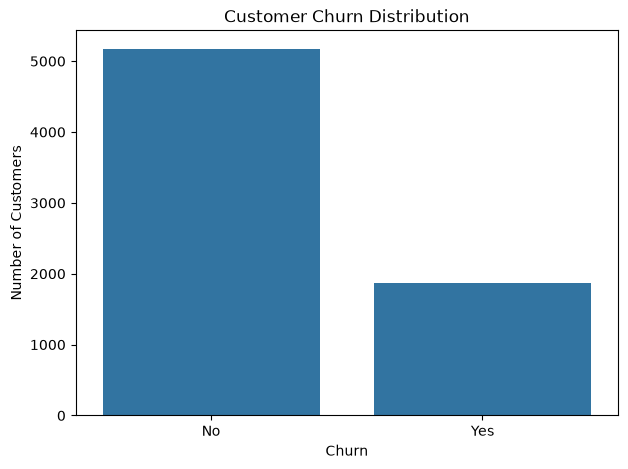

In [26]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

## 5.Investigate Customer Churn by Gender

We investigate whether customer churn rates differ between male and female customers.

In [27]:
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print(gender_churn.to_string())

Churn          No        Yes
gender                      
Female  73.079128  26.920872
Male    73.839662  26.160338


**Observation:**
- Out of all female customers, approximately 26.92% churned.
- Out of all male customers, approximately 26.16% churned.
- The difference in churn rates is approximately 0.76%, suggesting that gender has little apparent association with customer churn.

## 6. Investigate Customer Churn by Contract Type

We investigate the relationship between contract type and customer churn to determine whether customers on different contract plans exhibit different churn rates.

In [28]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.to_string())

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


**Observation:**
- Month-to-month: Approximately 42.71% of customers churned. This is the highest churn rate among the three contract types.
- One year: Approximately 11.27% of customers churned.
- Two year: Only approximately 2.83% of customers churned.
- Customers on month-to-month contracts have a substantially higher observed churn rate than customers on longer-term contracts.

## 7.Visualising Customer Churn by Contract Type

A grouped bar chart is used to compare customer churn percentages across the three contract types.

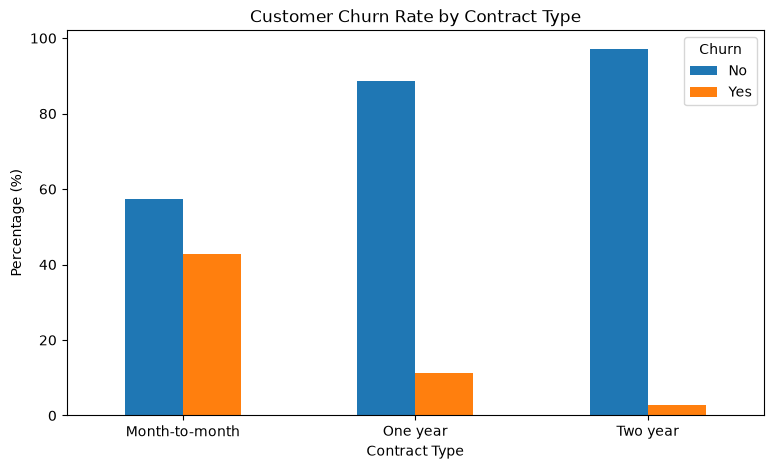

In [29]:
contract_churn.plot(kind="bar", figsize=(9, 5))

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")

plt.show()

## 8.Investigate Customer Churn by Tenure

We investigate the relationship between customer tenure and churn to determine whether customers who have been with the company for shorter or longer periods are more likely to leave.

In [30]:
print(df.groupby("Churn")["tenure"].describe().to_string())

        count       mean        std  min   25%   50%   75%   max
Churn                                                           
No     5174.0  37.569965  24.113777  0.0  15.0  38.0  61.0  72.0
Yes    1869.0  17.979133  19.531123  1.0   2.0  10.0  29.0  72.0


## 9.Visualising Customer Tenure by Churn

Boxplots are used to compare the distribution of customer tenure between customers who churned and those who stayed.

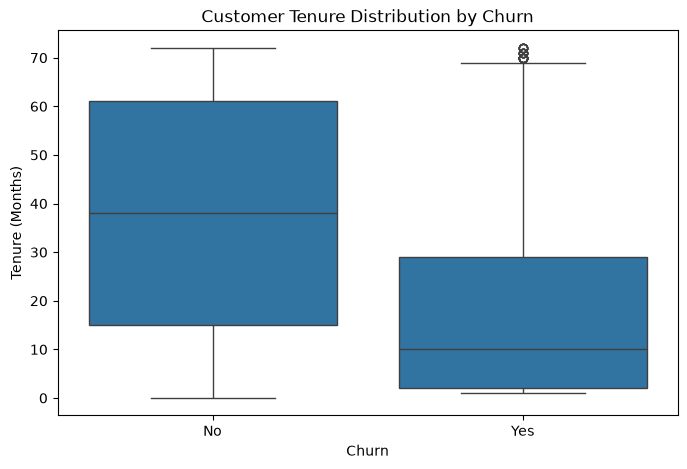

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

**Observation:**

Customers who churned generally had considerably shorter tenures than customers who remained with the company. The median tenure of churned customers was 10 months, compared with 38 months for customers who stayed. This suggests a strong association between shorter customer tenure and higher churn. Therefore, tenure may be an important predictive feature when developing the customer churn classification model.

## 10.Investigate Customer Churn by Monthly Charges

We investigate the relationship between monthly charges and customer churn to determine whether customers who pay higher monthly fees are more likely to leave the company.

In [32]:
print(df.groupby("Churn")["MonthlyCharges"].describe().to_string())

        count       mean        std    min    25%     50%   75%     max
Churn                                                                  
No     5174.0  61.265124  31.092648  18.25  25.10  64.425  88.4  118.75
Yes    1869.0  74.441332  24.666053  18.85  56.15  79.650  94.2  118.35


## 11.Visualising Monthly Charges by Churn

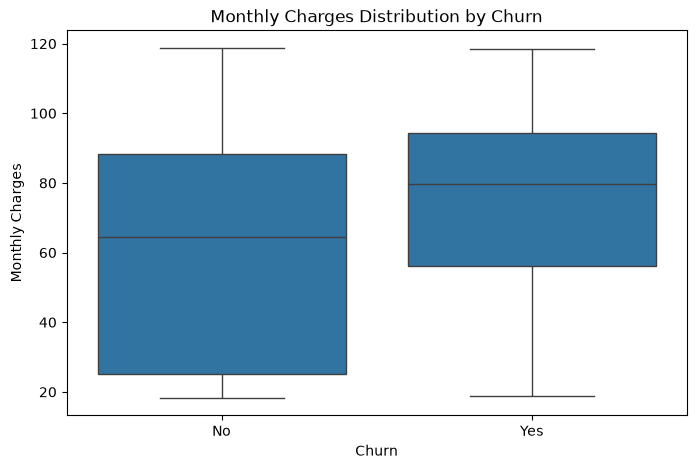

In [33]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

**Observation:**

Customers who churned generally had higher monthly charges than customers who remained with the company. The median monthly charge for churned customers was 79.65, compared with 64.43 for customers who stayed. This suggests a possible association between higher monthly charges and customer churn. However, monthly charges alone may not explain customer churn.

## 12.Investigate Customer Churn by Total Charges

We investigate the relationship between total charges and customer churn to understand how the accumulated charges of customers differ between those who stayed and those who left.

In [34]:
print(df.groupby("Churn")["TotalCharges"].describe().to_string())

        count         mean          std    min    25%       50%      75%      max
Churn                                                                            
No     5174.0  2549.911442  2329.954215   0.00  572.9  1679.525  4262.85  8672.45
Yes    1869.0  1531.796094  1890.822994  18.85  134.5   703.550  2331.30  8684.80


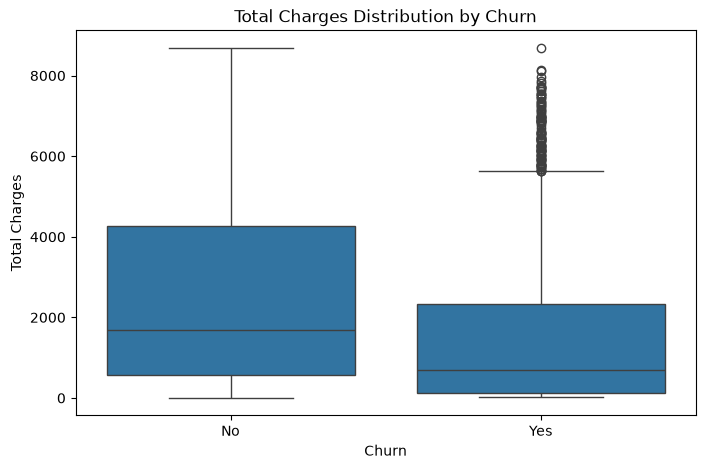

In [35]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Churn", y="TotalCharges")

plt.title("Total Charges Distribution by Churn")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

**Observation:**

Total charges are generally higher among customers who stayed. However, this is expected because customers with longer tenures have more time to accumulate charges. Therefore, total charges should be interpreted alongside tenure and monthly charges rather than as an independent indicator of customer churn.

## 13.Investigate Customer Churn by Internet Service

We investigate whether the type of internet service subscribed to by customers is associated with differences in customer churn rates.

In [36]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

print(internet_churn.to_string())

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


**Observation:**

Fiber optic customers exhibit the highest observed churn rate at approximately 41.89%, compared with 18.96% for DSL customers and 7.40% for customers without internet service. This suggests a strong association between internet service type and customer churn. Further investigation is required to understand why Fiber optic customers exhibit higher churn.

## 14.Investigate Customer Churn by Online Security and Tech Support

We investigate whether subscribing to Online Security and Tech Support is associated with differences in customer churn rates.

In [37]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

print("Online Security:")
print(security_churn.to_string())

print("\nTech Support:")
print(support_churn.to_string())

Online Security:
Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194

Tech Support:
Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


**Observation:**

Customers who do not subscribe to Online Security or Tech Support exhibit considerably higher churn rates than customers who subscribe to these services. The churn rate for customers without Online Security is approximately 41.77%, compared with 14.61% for customers with the service. Similarly, customers without Tech Support have a churn rate of 41.64%, compared with 15.17% for customers with the service.

These findings suggest that Online Security and Tech Support are strongly associated with customer retention. However, further investigation is required to determine whether these relationships are independent of other factors, such as contract type and tenure.

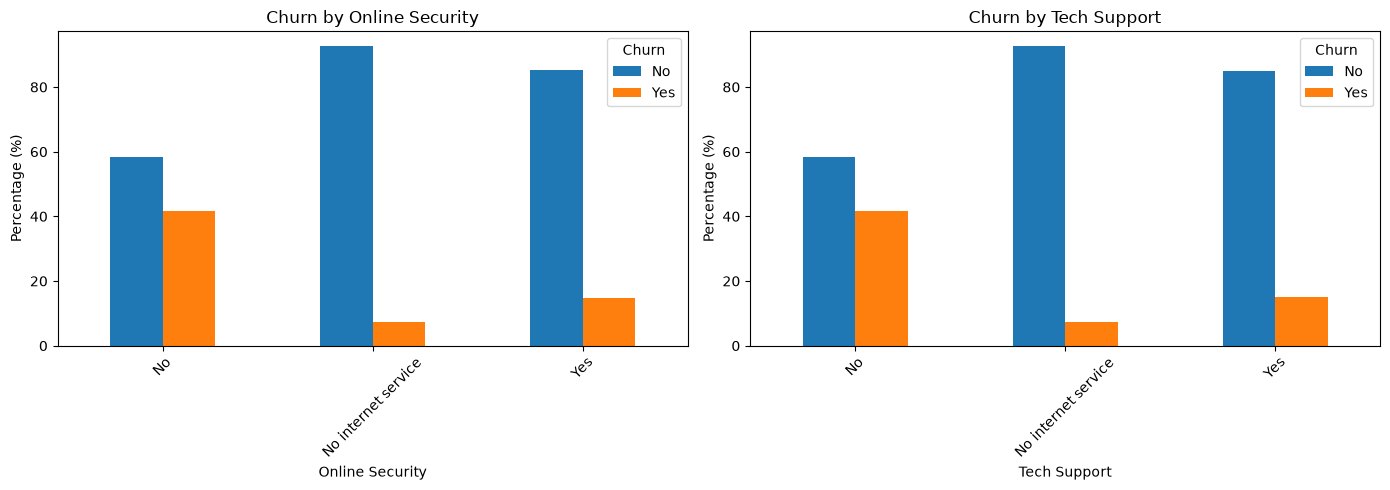

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

security_churn.plot(
    kind="bar",
    ax=axes[0]
)

axes[0].set_title("Churn by Online Security")
axes[0].set_xlabel("Online Security")
axes[0].set_ylabel("Percentage (%)")
axes[0].tick_params(axis="x", rotation=45)

support_churn.plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Churn by Tech Support")
axes[1].set_xlabel("Tech Support")
axes[1].set_ylabel("Percentage (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## 15.Investigate Customer Churn by Payment Method

We investigate whether customer churn rates differ according to the payment method used by customers.

In [39]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

print(payment_churn.to_string())

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


**Observation:**

Customers using electronic checks exhibit a considerably higher churn rate 45.29% compared with customers using other payment methods. Customers using automatic credit card payments have the lowest churn rate at approximately 15.24%. This suggests that payment method is strongly associated with customer churn. Further investigation is required to determine whether this relationship is influenced by other customer characteristics.

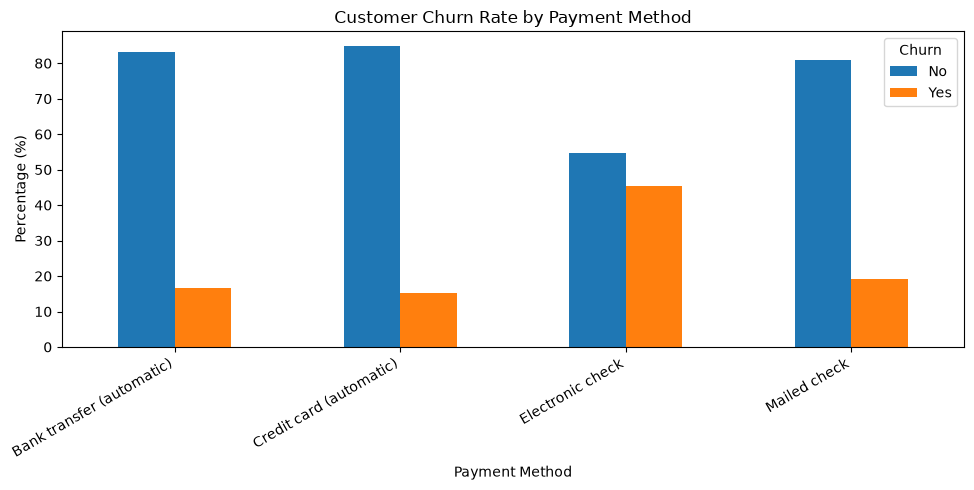

In [40]:
payment_churn.plot(kind="bar", figsize=(10, 5))

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Churn")

plt.tight_layout()
plt.show()

## 16.Investigate Customer Churn by Demographic Characteristics

We investigate whether customer demographic characteristics, including senior citizen status, partnership status and dependants, are associated with differences in customer churn rates.

In [41]:
demographic_columns = ["SeniorCitizen", "Partner", "Dependents"]

for column in demographic_columns:
    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(f"\nCustomer Churn by {column}:")
    print(churn_rate.to_string())


Customer Churn by SeniorCitizen:
Churn                 No        Yes
SeniorCitizen                      
0              76.393832  23.606168
1              58.318739  41.681261

Customer Churn by Partner:
Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903

Customer Churn by Dependents:
Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237


**Observations:**

The demographic analysis reveals differences in churn rates across customer groups. Senior citizens exhibit a higher churn rate (41.68%) than non-senior customers (23.61%). Customers without partners also have a higher churn rate (32.96%) than those with partners (19.66%). Similarly, customers without dependants have a higher churn rate (31.28%) compared with customers who have dependants (15.45%).

These findings suggest that demographic characteristics may be useful predictive features when identifying customers at risk of churning. However, further statistical analysis is required to assess the significance of these relationships.

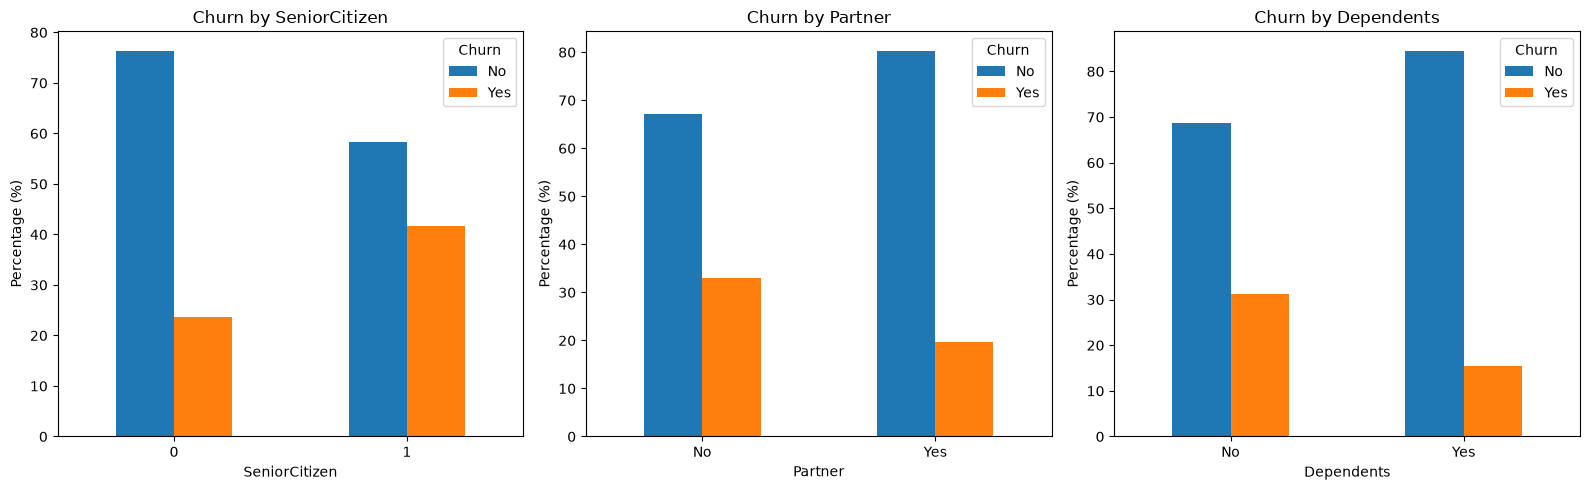

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, demographic_columns):

    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    churn_rate.plot(kind="bar", ax=ax)

    ax.set_title(f"Churn by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Percentage (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Churn")

plt.tight_layout()
plt.show()

## 17.Investigate Customer Churn by Additional Services

We investigate whether subscribing to additional telecom services is associated with differences in customer churn rates.

In [43]:
service_columns = [
    "MultipleLines",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies"
]

for column in service_columns:
    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(f"\nCustomer Churn by {column}:")
    print(churn_rate.to_string())


Customer Churn by MultipleLines:
Churn                    No        Yes
MultipleLines                         
No                74.955752  25.044248
No phone service  75.073314  24.926686
Yes               71.390104  28.609896

Customer Churn by OnlineBackup:
Churn                       No        Yes
OnlineBackup                             
No                   60.071244  39.928756
No internet service  92.595020   7.404980
Yes                  78.468506  21.531494

Customer Churn by DeviceProtection:
Churn                       No        Yes
DeviceProtection                         
No                   60.872375  39.127625
No internet service  92.595020   7.404980
Yes                  77.497936  22.502064

Customer Churn by StreamingTV:
Churn                       No        Yes
StreamingTV                              
No                   66.476868  33.523132
No internet service  92.595020   7.404980
Yes                  69.929812  30.070188

Customer Churn by StreamingMovies:
Chu

The analysis reveals that Online Backup and Device Protection have noticeable associations with customer churn. Customers without these services exhibit higher churn rates than those who subscribe to them. In contrast, Multiple Lines, Streaming TV and Streaming Movies show relatively smaller differences in churn rates.

These findings suggest that certain additional services may be useful predictive features when identifying customers at risk of churning. However, the observed relationships may overlap with other customer characteristics, such as internet service type and contract type.

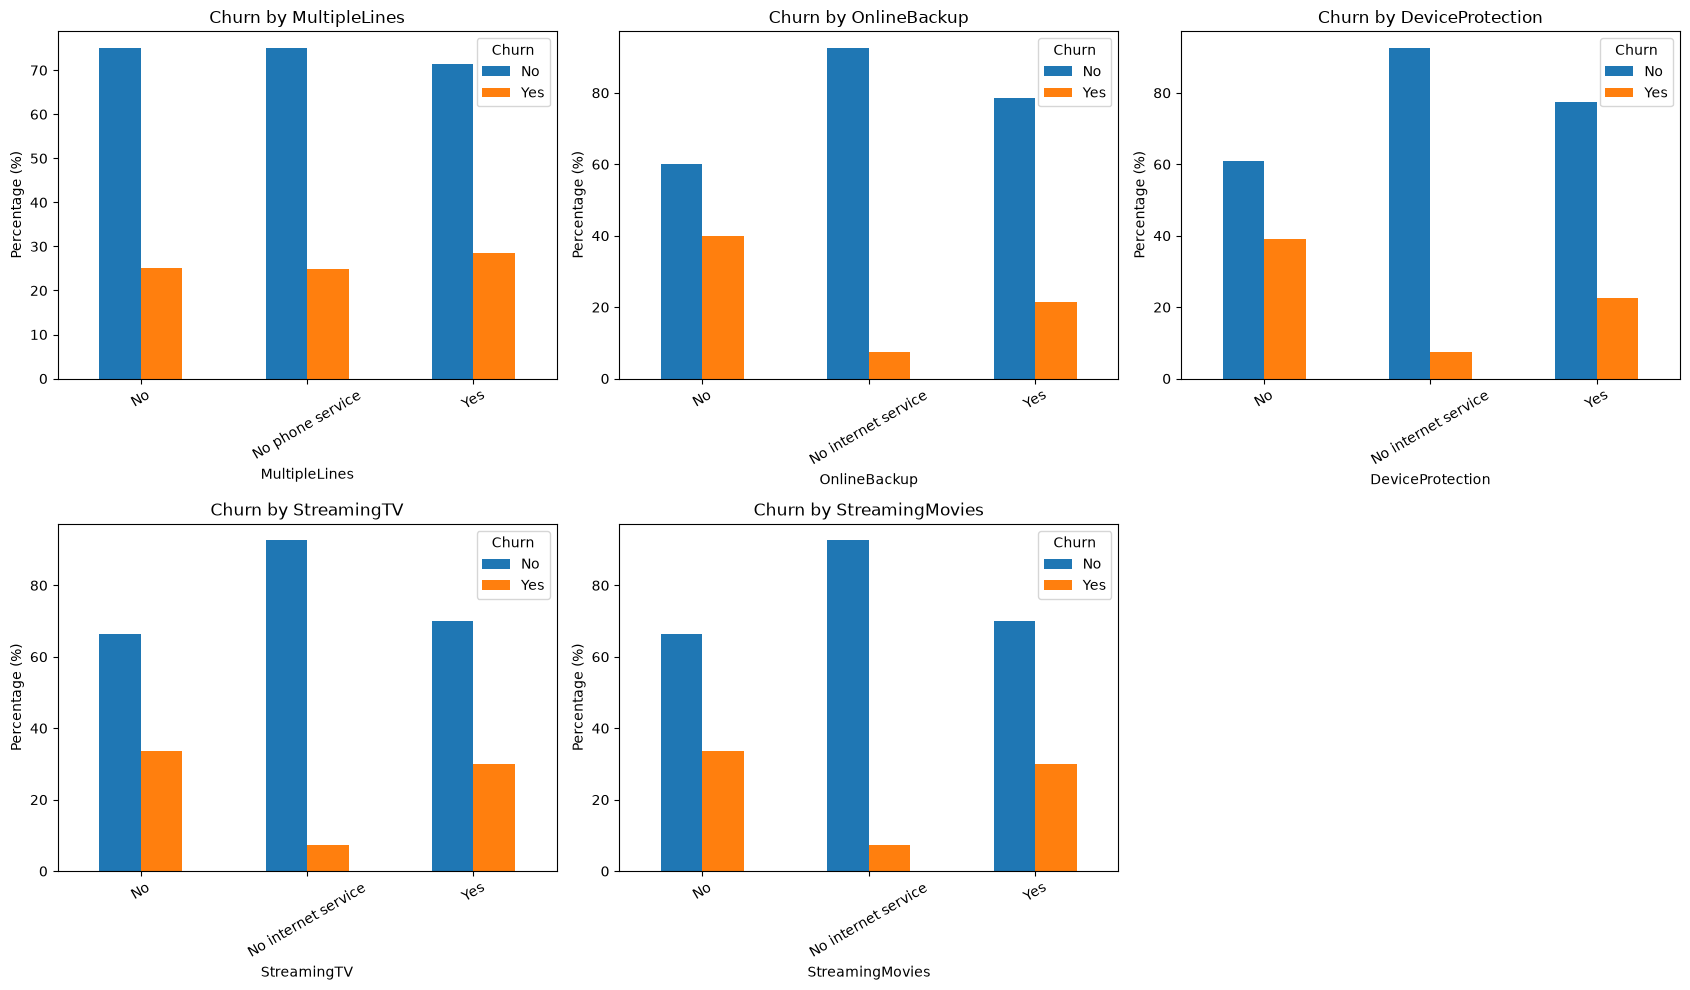

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))

for ax, column in zip(axes.flatten(), service_columns):

    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    churn_rate.plot(kind="bar", ax=ax)

    ax.set_title(f"Churn by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Percentage (%)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Churn")

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

## 18.Investigate Customer Churn by Billing and Phone Services

We investigate whether paperless billing and phone service subscriptions are associated with differences in customer churn rates.

In [45]:
remaining_columns = ["PaperlessBilling", "PhoneService"]

for column in remaining_columns:
    churn_rate = pd.crosstab(
        df[column],
        df["Churn"],
        normalize="index"
    ) * 100

    print(f"\nCustomer Churn by {column}:")
    print(churn_rate.to_string())


Customer Churn by PaperlessBilling:
Churn                    No        Yes
PaperlessBilling                      
No                83.669916  16.330084
Yes               66.434908  33.565092

Customer Churn by PhoneService:
Churn                No        Yes
PhoneService                      
No            75.073314  24.926686
Yes           73.290363  26.709637


**Observation:**

The churn rates are relatively close, with a difference of only 1.78%.
This suggests that having a phone service does not show a particularly strong association with customer churn.

## 19.Summary of Exploratory Data Analysis

The exploratory data analysis revealed several patterns associated with customer churn:

- Contract type: Month-to-month customers have substantially higher churn rates than customers on one-year or two-year contracts.
- Tenure: Customers who churn generally have shorter tenures than customers who remain.
- Internet service: Fiber optic customers show higher churn rates than DSL and customers without internet service.
- Additional services: Customers without OnlineSecurity, TechSupport, OnlineBackup and DeviceProtection generally have higher churn rates.
- Payment method: Customers paying through electronic checks have notably higher churn rates.
- Billing: Customers using paperless billing have higher observed churn rates.
- Demographics: Senior citizens and customers without partners or dependents show higher churn rates.
- Monthly charges: Customers who churn generally have higher monthly charges.
- Gender and phone service: These variables show relatively small differences in churn rates.
- Total charges: TotalCharges should be interpreted alongside tenure because customers who remain longer have more time to accumulate charges.

These findings represent descriptive associations and do not establish causation. Further statistical analysis and predictive modelling will help determine which features are most useful for predicting customer churn.

# Part C : Statistical Analysis and Hypothesis Testing(categorical)

## 1.Customer Churn and Contract Type test of association

In [46]:
from scipy.stats import chi2_contingency

Create a Contingency Table to test association between Churn  and Contract

In [47]:
contract_table = pd.crosstab(df["Contract"], df["Churn"])

print(contract_table)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


Perform Chi-Square test at a significance level of 0.05

In [48]:
chi2, p_value, dof, expected = chi2_contingency(contract_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 1184.5965720837926
P-value: 5.863038300673391e-258
Degrees of freedom: 2


### Interpretation: Contract Type and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Contract type and customer churn are independent.
- **Alternative Hypothesis (H₁):** Contract type and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than the significance level of 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between contract type and customer churn.

This supports the pattern observed during exploratory data analysis, where month-to-month customers demonstrated considerably higher churn rates than customers with longer-term contracts.

## 2.Customer Churn and Payment Method test of association

In [49]:
payment_table = pd.crosstab(df["PaymentMethod"], df["Churn"])

print(payment_table)

Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308


In [50]:
chi2, p_value, dof, expected = chi2_contingency(payment_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 648.1423274814
P-value: 3.6823546520097993e-140
Degrees of freedom: 3


### Interpretation: Payment Method and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Payment method and customer churn are independent.
- **Alternative Hypothesis (H₁):** Payment method and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than the significance level of 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between payment method and customer churn.

This supports the pattern observed during exploratory data analysis, where customers using electronic checks demonstrated considerably higher churn rates than customers using other payment methods.

## 3.Customer Churn and Internet Service test of association

In [51]:
internet_table = pd.crosstab(df["InternetService"], df["Churn"])

print(internet_table)

Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113


In [52]:
chi2, p_value, dof, expected = chi2_contingency(internet_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 732.309589667794
P-value: 9.571788222840544e-160
Degrees of freedom: 2


### Interpretation: Internet Service and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Internet service type and customer churn are independent.
- **Alternative Hypothesis (H₁):** Internet service type and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than the significance level of 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between internet service type and customer churn.

This supports the pattern observed during exploratory data analysis, where fiber optic customers demonstrated considerably higher churn rates than DSL customers and customers without internet service.

## 4.Customer Churn and Online Security test of association

In [53]:
security_table = pd.crosstab(df["OnlineSecurity"], df["Churn"])

print(security_table)

Churn                  No   Yes
OnlineSecurity                 
No                   2037  1461
No internet service  1413   113
Yes                  1724   295


In [54]:
chi2, p_value, dof, expected = chi2_contingency(security_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 849.9989679615965
P-value: 2.661149635176552e-185
Degrees of freedom: 2


### Interpretation: Online Security and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Online security subscription and customer churn are independent.
- **Alternative Hypothesis (H₁):** Online security subscription and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than the significance level of 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between online security subscription and customer churn.

This supports the pattern observed during exploratory data analysis, where customers without online security demonstrated considerably higher churn rates than customers who subscribed to online security.

## 5.Customer Churn and Technical Support test of association

In [55]:
support_table = pd.crosstab(df["TechSupport"], df["Churn"])

print(support_table)

Churn                  No   Yes
TechSupport                    
No                   2027  1446
No internet service  1413   113
Yes                  1734   310


In [56]:
chi2, p_value, dof, expected = chi2_contingency(support_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 828.1970684587394
P-value: 1.4430840279998987e-180
Degrees of freedom: 2


### Interpretation: Technical Support and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Technical Support subscription and customer churn are independent.
- **Alternative Hypothesis (H₁):** Technical Support subscription and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than the significance level of 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between technical support subscription and customer churn.

This supports the pattern observed during EDA: customers without technical support had a considerably higher churn rate (41.64%) than customers with technical support (15.17%).

This does not establish that having technical support causes customers to stay. It shows that the two variables are statistically associated.

## 6.Customer Churn and Paperless billing test of association

In [57]:
paperless_table = pd.crosstab(df["PaperlessBilling"], df["Churn"])
print(paperless_table)

Churn               No   Yes
PaperlessBilling            
No                2403   469
Yes               2771  1400


In [58]:
chi2, p_value, dof, expected = chi2_contingency(paperless_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 258.27764906707307
P-value: 4.073354668665985e-58
Degrees of freedom: 1


### Interpretation: Paperless Billing and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Paperless billing status and customer churn are independent.
- **Alternative Hypothesis (H₁):** Paperless billing status and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between paperless billing status and customer churn.

This supports our EDA findings: customers using paperless billing had a higher churn rate than customers not using paperless billing.

This association does not establish that paperless billing causes customers to churn.

## 7.Customer Churn and Senior Citizen Status test of association

In [59]:
senior_table = pd.crosstab(df["SeniorCitizen"], df["Churn"])
print(senior_table)

Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476


In [60]:
chi2, p_value, dof, expected = chi2_contingency(senior_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 159.42630036838742
P-value: 1.510066805092378e-36
Degrees of freedom: 1


### Intepretation: Senior Citizen Status and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Senior citizen status and customer churn are independent.
- **Alternative Hypothesis (H₁):** Senior citizen status and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between senior citizen status and customer churn.

This supports our EDA findings: senior citizens had a considerably higher churn rate than non-senior citizens.

This association does not establish that senior citizen status causes customers to churn.

## 8.Customer Churn and Partner Status test of association

In [61]:
partner_table = pd.crosstab(df["Partner"], df["Churn"])
print(partner_table)

Churn      No   Yes
Partner            
No       2441  1200
Yes      2733   669


In [62]:
chi2, p_value, dof, expected = chi2_contingency(partner_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 158.7333820309922
P-value: 2.1399113440759935e-36
Degrees of freedom: 1


### Intepretation: Partner Status and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Partner status and customer churn are independent.
- **Alternative Hypothesis (H₁):** Partner status and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between partner status and customer churn.

This supports our EDA findings: customers without partners had a higher churn rate than customers with partners.

This association does not establish that partner status causes customers to churn.

## 9.Customer Churn and Dependents Status test of association

In [63]:
dependents_table = pd.crosstab(df["Dependents"], df["Churn"])
print(dependents_table)

Churn         No   Yes
Dependents            
No          3390  1543
Yes         1784   326


In [64]:
chi2, p_value, dof, expected = chi2_contingency(dependents_table)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Chi-square statistic: 189.12924940423474
P-value: 4.9249216612154196e-43
Degrees of freedom: 1


### Intepretation: Dependents and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** Dependents status and customer churn are independent.
- **Alternative Hypothesis (H₁):** Dependents status and customer churn are not independent.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence of an association between dependents status and customer churn.

This supports our EDA findings: customers without dependents had a higher churn rate (31.28%) than customers with dependents (15.45%).

This association does not establish that dependents status causes customers to churn.

# Part D : Statistical Analysis and Hypothesis Testing(numerical)

For numerical variables, we'll use the Mann–Whitney U test. This test compares the distributions of a numerical variable between two independent groups—in our case, customers who churned (Yes) and customers who stayed (No).

In [65]:
from scipy.stats import mannwhitneyu

## 1.Mann–Whitney U Test: Tenure and Customer Churn

In [66]:
tenure_stayed = df[df["Churn"] == "No"]["tenure"]
tenure_churned = df[df["Churn"] == "Yes"]["tenure"]

u_statistic, p_value = mannwhitneyu(
    tenure_churned,
    tenure_stayed,
    alternative="less"
)

print("Mann-Whitney U statistic:", u_statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 2515538.0
P-value: 1.209817758975933e-208


### Interpretation: Tenure and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** There is no difference in the tenure distributions of customers who churned and customers who stayed.
- **Alternative Hypothesis (H₁):** Customers who churned tend to have shorter tenures than customers who stayed.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence that customers who churned tend to have shorter tenures than customers who stayed.

This supports our EDA findings, where customers who churned had a considerably lower median tenure than customers who remained with the company.

## 2.Mann–Whitney U Test: MonthlyCharges and Customer Churn

In [67]:
charges_stayed = df[df["Churn"] == "No"]["MonthlyCharges"]
charges_churned = df[df["Churn"] == "Yes"]["MonthlyCharges"]

u_statistic, p_value = mannwhitneyu(
    charges_churned,
    charges_stayed,
    alternative="greater"
)

print("Mann-Whitney U statistic:", u_statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 6003125.5
P-value: 1.6558138259942924e-54


### Interpretation: MonthlyCharges and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** There is no difference in the MonthlyCharges distributions of customers who churned and customers who stayed.
- **Alternative Hypothesis (H₁):** Customers who churned tend to have higher MonthlyCharges than customers who stayed.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence that customers who churned tend to have higher MonthlyCharges than customers who stayed.

This supports our EDA findings, where customers who churned had a considerably higher median MonthlyCharges than customers who remained with the company.

## 3.Mann–Whitney U Test: TotalCharges and Customer Churn

In [68]:
total_stayed = df[df["Churn"] == "No"]["TotalCharges"]
total_churned = df[df["Churn"] == "Yes"]["TotalCharges"]

u_statistic, p_value = mannwhitneyu(
    total_churned,
    total_stayed,
    alternative="less"
)

print("Mann-Whitney U statistic:", u_statistic)
print("P-value:", p_value)

Mann-Whitney U statistic: 3381224.0
P-value: 2.842516933103657e-83


### Interpretation: TotalCharges and Customer Churn

**Hypotheses**

- **Null Hypothesis (H₀):** There is no difference in the TotalCharges distributions of customers who churned and customers who stayed.
- **Alternative Hypothesis (H₁):** Customers who churned tend to have lower TotalCharges than customers who stayed.

**Significance level (α): 0.05**

**Decision**

Since the p-value is significantly smaller than 0.05, we reject the null hypothesis.

**Conclusion**

There is statistically significant evidence that customers who churned tend to have lower TotalCharges than customers who stayed.

This supports our EDA findings, where customers who churned had a considerably lower median TotalCharges than customers who remained with the company.

One important analytical observation: TotalCharges is strongly influenced by both tenure and MonthlyCharges. Since churned customers generally have shorter tenures, their lower TotalCharges may partly reflect the shorter period they remained customers. We should avoid interpreting this as evidence that lower total charges cause churn.

# Part E : Measuring Strength of Categorical variables

### Measure the strenght of association for categorical variables using Cramer's V

Cramér's V ranges from 0 to 1:

- 0 indicates no association.
- Values closer to 1 indicate stronger associations.

In [69]:
import numpy as np

def cramers_v(contingency_table):
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)

    n = contingency_table.to_numpy().sum()
    rows, columns = contingency_table.shape

    v = np.sqrt(chi2 / (n * min(rows - 1, columns - 1)))

    return v

A reusable function that  calculates Cramer's V

In [70]:
categorical_variables = [
    "Contract",
    "PaymentMethod",
    "InternetService",
    "OnlineSecurity",
    "TechSupport",
    "PaperlessBilling",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

cramers_results = {}

for variable in categorical_variables:
    contingency_table = pd.crosstab(df[variable], df["Churn"])
    cramers_results[variable] = cramers_v(contingency_table)

cramers_results = pd.Series(cramers_results, name="Cramer's V")
cramers_results = cramers_results.sort_values(ascending=False)

print(cramers_results)

Contract            0.410116
OnlineSecurity      0.347400
TechSupport         0.342916
InternetService     0.322455
PaymentMethod       0.303359
PaperlessBilling    0.191498
Dependents          0.163870
SeniorCitizen       0.150453
Partner             0.150126
Name: Cramer's V, dtype: float64


### Interpretation: Cramér's V Results

The Cramér's V results provide insight into the strength of association between categorical variables and customer churn.

The results indicate that Contract has the strongest association with customer churn, followed by OnlineSecurity, TechSupport, InternetService and PaymentMethod.

PaperlessBilling, Dependents, SeniorCitizen and Partner demonstrate comparatively weaker associations with customer churn.

These findings complement the Chi-square tests by showing that statistical significance does not necessarily imply a strong association.

Contract appears to be particularly important because it demonstrated the strongest association with customer churn. This supports the patterns observed during exploratory data analysis.

However, association strength alone does not establish predictive importance or causation. Further investigation through classification modelling will help determine how these variables contribute to predicting customer churn.

# Part F : Statistical Analysis Summary

The statistical analysis was conducted to investigate relationships between customer characteristics and churn.

The Chi-square tests identified statistically significant associations between all nine selected categorical variables and customer churn.

The Mann–Whitney U tests also identified statistically significant differences in the distributions of tenure, MonthlyCharges and TotalCharges between customers who churned and those who stayed.

Cramér's V was used to measure the strength of associations between categorical variables and customer churn. Contract demonstrated the strongest association, followed by OnlineSecurity, TechSupport, InternetService and PaymentMethod.

Overall, the statistical analysis supports the patterns identified during exploratory data analysis. These findings provide a foundation for the next stage of the project: feature engineering and predictive modelling.

Statistical associations do not establish causation, and the predictive importance of individual variables will be investigated further during model development.

# Part G : Feature Engineering and Data Preprocessing

This section prepares the cleaned customer churn dataset for machine learning.

The objective is to transform the dataset into a format suitable for classification modelling while ensuring that data leakage is avoided.

The preprocessing steps will include:
- Separating the target variable from the predictor variables.
- Removing irrelevant columns.
- Identifying numerical and categorical features.
- Encoding categorical variables.
- Splitting the dataset into training and testing sets.

## 1.Seperate features and target

Before preprocessing, we need to separate:
- Features (X): Customer information that the model will use to make predictions.
- Target (y): The outcome we want to predict, which is Churn.

In [71]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

## 2.Inspect the features and the target

In [72]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


## 3.Identify numerical and categorical features

In [73]:
numerical_features = X.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X.select_dtypes(include=["str", "object", "category"]).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 4.Choose encoding strategy for categorical variables

The dataset contains numerical and categorical features, which require different preprocessing techniques.

**Numerical features:**
- StandardScaler will be used to standardise numerical features.
- This ensures that numerical variables are on comparable scales, which is particularly important for Logistic Regression.

**Categorical features:**
- OneHotEncoder will be used to convert categorical variables into numerical representations.
- This prevents the model from interpreting nominal categories as having an artificial numerical order.

**Preprocessing implementation:**

Scikit-learn's ColumnTransformer and Pipeline will be used to apply these transformations.

The preprocessing transformations will be fitted using the training data only to prevent data leakage.

## 5.Split the dataset
We'll divide our dataset into:
- 80% training data: Used to train the model.
- 20% testing data: Used to evaluate how well the model performs on unseen data.

In [74]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

## 6.Verify the train-test split
Before preprocessing, let's verify the sizes and churn proportions in both datasets.

In [75]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     73.456352
Yes    26.543648
Name: proportion, dtype: float64


## 7.Build the preprocessing pipeline
Now we get to the actual conversion!

We'll use three Scikit-learn components:
- StandardScaler: Standardises numerical features.
- OneHotEncoder: Converts categorical features into binary columns.
- ColumnTransformer: Applies the appropriate transformation to each feature group.

In [76]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

## 8.Fit and transform the training data

In [77]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

## 9.Inspect the transformed data
Let's check the dimensions and confirm that the transformation worked.

In [78]:
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

Original training shape: (5634, 19)
Processed training shape: (5634, 45)

Original testing shape: (1409, 19)
Processed testing shape: (1409, 45)


The OneHotEncoder transformed the 15 categorical features into 41 binary columns.

## 10.Final preprocessing verification
Before moving to modelling, let's check whether the transformed data contains any missing or infinite values.

In [79]:
import numpy as np

print("Missing values:", np.isnan(X_train_processed).sum())
print("Infinite values:", np.isinf(X_train_processed).sum())

Missing values: 0
Infinite values: 0


## 11.Preprocessing Summary

The dataset was prepared for machine learning through the following steps:

1. Separated the predictor variables (X) from the target variable (y).
2. Removed the customerID column because it is an identifier rather than a predictive feature.
3. Identified 4 numerical features and 15 categorical features.
4. Split the dataset into training (80%) and testing (20%) sets using stratified sampling.
5. Standardised numerical features using StandardScaler.
6. Applied One-Hot Encoding to categorical features using OneHotEncoder.
7. Used a ColumnTransformer to apply the appropriate transformations.
8. Fitted the preprocessing transformations on the training data and applied them to the testing data.

The original 19 features were transformed into 45 numerical features.

The final verification confirmed that there are no missing or infinite values in the processed datasets.

The data is now ready for classification modelling.

# Part H : Predictive Modelling

## This section focuses on improving the baseline Logistic Regression model through different optimisation techniques.

The following approaches will be explored:

- **Decision Threshold Tuning:** Experimenting with different classification thresholds to find a better balance between precision and recall.
- **Alternative Classification Algorithms:** Exploring models such as Random Forest and Gradient Boosting to determine whether they offer better predictive performance.

The objective is to improve the model's ability to identify customers who are likely to churn while maintaining a reasonable balance between false positives and false negatives.

## 1.Import Logistic Regression
We'll use Scikit-learn's LogisticRegression class.


In [80]:
from sklearn.linear_model import LogisticRegression

## 2.nitialise the Logistic Regression model

In [81]:
logistic_model = LogisticRegression(random_state=42)

## 3.Train the Logistic Regression model
Let the model learn patterns from our training data.

In [82]:
logistic_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solve

## 4.Generate predictions
We'll use the trained model to predict whether customers in our testing dataset will churn or stay

In [83]:
y_pred = logistic_model.predict(X_test_processed)

## 5.Inspect the predictions
Before evaluating the model, look at a few predictions.

In [84]:
print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_test.iloc[:10].values)

First 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']

First 10 actual values:
<StringArray>
['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes']
Length: 10, dtype: str


We have:
- 7 correct predictions.
- 3 incorrect predictions.

## 6.Evaluate model accuracy
Let's calculate the percentage of predictions that were correct from the 1409 observations. 

In [85]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4f}")
print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 0.8055
Model Accuracy: 80.55%


## 7.Confusion Matrix

A confusion matrix is an evaluation tool used in classification problems to compare the actual target values with the predictions made by a machine learning model.

It provides a breakdown of the model's predictions into four categories:

- **True Negative (TN):** The model correctly predicts that a customer will stay.
- **False Positive (FP):** The model predicts that a customer will churn, but the customer actually stays.
- **False Negative (FN):** The model predicts that a customer will stay, but the customer actually churns.
- **True Positive (TP):** The model correctly predicts that a customer will churn.

The confusion matrix helps identify the types of classification errors made by the model.

In customer churn prediction, False Negatives are particularly important because they represent customers who are likely to leave but were not identified by the model. Identifying these customers is important for developing effective customer retention strategies.

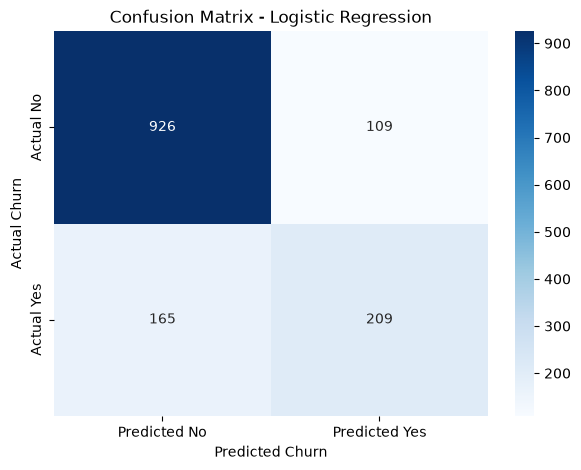

In [86]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=["No", "Yes"])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Churn")
plt.ylabel("Actual Churn")
plt.show()

### Interpretation: Confusion Matrix

The confusion matrix provides a breakdown of the Logistic Regression model's classification results.

The model produced the following results:

- **True Negatives (926):** The model correctly predicted that 926 customers would stay.
- **False Positives (109):** The model predicted that 109 customers would churn, but they actually stayed.
- **False Negatives (165):** The model predicted that 165 customers would stay, but they actually churned.
- **True Positives (209):** The model correctly predicted that 209 customers would churn.

The model performs better at identifying customers who stayed than customers who churned.
An important observation is that the model failed to identify 165 customers who actually churned. This is particularly important because identifying potential churners is a key objective of this project.

Further evaluation using precision, recall and F1-score will provide a deeper understanding of the model's classification performance.

## 8.Precision
Precision measures how many customers predicted to churn actually churned. In other words, it tells us how reliable the model's churn predictions are.

In [87]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_pred, pos_label="Yes")

print(f"Precision: {precision * 100:.2f}%")

Precision: 65.72%


This means that approximately 66% of the customers the model predicted would churn actually churned.

The remaining 34% were false positives — customers predicted to churn who actually stayed.

## 9.Recall
Recall measures the proportion of actual churners that the model correctly identified.

In [88]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_pred, pos_label="Yes")

print(f"Recall: {recall * 100:.2f}%")

Recall: 55.88%


This means the model correctly identified approximately 56% of all customers who actually churned.

## 10.F1-score
The F1-score combines precision and recall using their harmonic mean. It gives us a single measure that balances both metrics.

In [89]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_pred, pos_label="Yes")

print(f"F1-score: {f1 * 100:.2f}%")

F1-score: 60.40%


### Interpretation: F1-score

The F1-score combines precision and recall into a single metric using their harmonic mean.

The model achieved an F1-score of 60.40%, indicating a moderate balance between its ability to correctly identify customers who churned and the reliability of its churn predictions.

This suggests that the Logistic Regression model provides a reasonable baseline, but improvements may be needed to identify a greater proportion of customers at risk of churning.

## 11.ROC-AUC Score

The Receiver Operating Characteristic - Area Under the Curve (ROC-AUC) measures how effectively the Logistic Regression model distinguishes between customers who churn and customers who stay.

The ROC-AUC score represents the model's ability to distinguish between the two classes across different classification thresholds.

A higher ROC-AUC score indicates better class discrimination.

**Interpretation of ROC-AUC:**

- **0.5:** The model performs no better than random guessing.
- **0.6 – 0.7:** Poor discrimination.
- **0.7 – 0.8:** Acceptable discrimination.
- **0.8 – 0.9:** Excellent discrimination.
- **0.9 – 1.0:** Outstanding discrimination.

In [90]:
# Identify the column representing churn (Yes)
yes_index = list(logistic_model.classes_).index("Yes")

# Generate predicted churn probabilities
y_prob = logistic_model.predict_proba(X_test_processed)[:, yes_index]

print(y_prob[:10])

[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [91]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC: {roc_auc:.4f}")

ROC-AUC: 0.8421


## 12.Plot the ROC Curve
The ROC curve provides a visual representation of the model's ability to distinguish between the two classes at different classification thresholds.

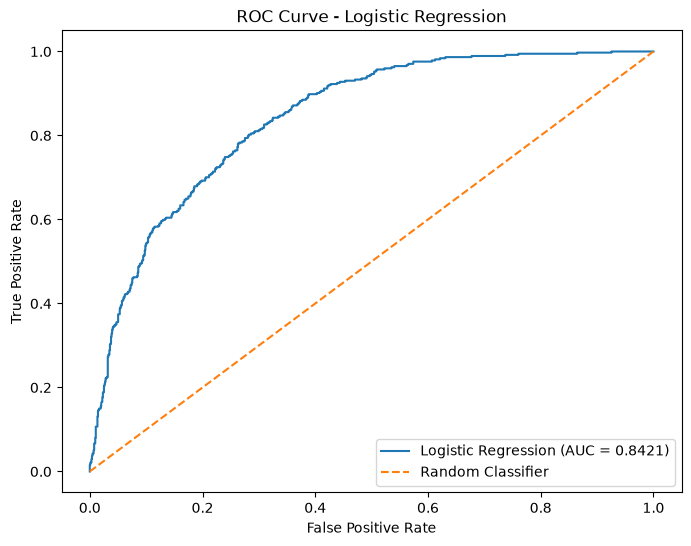

In [92]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob, pos_label="Yes")

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

### Interpretation: ROC Curve

The ROC curve illustrates the relationship between the True Positive Rate (TPR) and False Positive Rate (FPR) at different classification thresholds.

The curve demonstrates the Logistic Regression model's ability to distinguish between customers who churned and customers who stayed.

A curve that moves closer to the top-left corner indicates better discriminatory performance, as it achieves a higher True Positive Rate while maintaining a lower False Positive Rate.

The diagonal reference line represents the performance of a random classifier.

The ROC curve, together with the ROC-AUC score of 0.8421, indicates that the Logistic Regression model has good discriminatory ability.

## 13.Classification Report

The classification report provides a detailed summary of the Logistic Regression model's performance for each target class.

It includes the following evaluation metrics:

- **Precision:** The proportion of customers predicted to belong to a class who actually belong to that class.
- **Recall:** The proportion of customers belonging to a class that the model correctly identified.
- **F1-score:** The harmonic mean of precision and recall.
- **Support:** The number of actual observations belonging to each class in the test dataset.

The classification report evaluates both customer groups (No and Yes), providing a more comprehensive assessment of the model's classification performance.

It also includes macro and weighted averages to summarise the model's overall performance across both classes.

In [93]:
from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred)

print(report)

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1035
         Yes       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Interpretation: Classification Report

The classification report provides an overview of the Logistic Regression model's performance across both customer classes.

**1. Customers who stayed (No)**

- **Precision (85%):** Of all customers predicted to stay, 85% actually stayed.
- **Recall (89%):** The model correctly identified 89% of all customers who actually stayed.
- **F1-score (87%):** Indicates a strong balance between precision and recall for this class.

**2. Customers who churned (Yes)**

- **Precision (66%):** Of all customers predicted to churn, 66% actually churned.
- **Recall (56%):** The model correctly identified only 56% of all customers who actually churned.
- **F1-score (60%):** Indicates a weaker balance between precision and recall for this class.

**3. Macro average**

The macro average calculates the arithmetic mean of each metric across the two classes, treating both classes equally, regardless of their sizes.

For example, the macro average precision is calculated as:

$$
\frac{0.85 + 0.66}{2} = 0.755
$$

This gives approximately 0.75 (75%) in the classification report.

**4. Weighted average**

The weighted average calculates the average of each metric across the two classes while accounting for the number of actual observations in each class (support).

The weighted average is calculated using the following formula:

$$
\text{Weighted Average} =
\frac{(M_1 \times S_1) + (M_2 \times S_2)}
{S_1 + S_2}
$$

Where:
- $M_1$ and $M_2$ represent the metric values for each class.
- $S_1$ and $S_2$ represent the support (number of actual observations) for each class.

For example, the weighted average precision is calculated as:

$$
\frac{(0.85 \times 1035) + (0.66 \times 374)}
{1035 + 374}
$$

$$
= \frac{879.75 + 246.84}{1409}
$$

$$
= 0.7994 \approx 0.80
$$

Therefore, the weighted average precision is approximately 80%.

Since there are more customers who stayed (1,035) than customers who churned (374), the metrics for the "No" class have a greater influence on the weighted average.

This provides an overall performance measure that accounts for the class distribution.

**5. Overall accuracy**

The model achieved an accuracy of approximately 81%, meaning that it correctly classified around 81% of all customers in the test dataset.

**Overall observation**

The model performs better when identifying customers who stayed than customers who churned. This is particularly important because identifying potential churners is the primary objective of this project.

The relatively lower recall of 56% for the churn class indicates that the model fails to identify a considerable proportion of actual churners. Therefore, improving the model's ability to identify customers at risk of churning should be a priority in subsequent modelling stages.

## 14.Baseline Model Evaluation Summary

The Logistic Regression model was evaluated using several classification metrics to assess its ability to predict customer churn.

**1. Overall performance**

- **Accuracy (80.55%):** The model correctly classified approximately 81% of customers in the test dataset.
- **Precision (65.72%):** Of all customers predicted to churn, approximately 66% actually churned.
- **Recall (55.88%):** The model correctly identified approximately 56% of all actual churners.
- **F1-score (60.40%):** Indicates a moderate balance between precision and recall for the churn class.
- **ROC-AUC (0.8421):** Indicates good discriminatory ability, meaning the model can distinguish between customers who churn and those who stay across different classification thresholds.

**2. Key observations**

The model performs better at identifying customers who stayed than customers who churned.

Although the model achieved an accuracy of 80.55%, the majority-class baseline (predicting that every customer would stay) would achieve approximately 73.46% accuracy. Therefore, the Logistic Regression model performs better than this simple baseline.

However, the churn recall of 55.88% indicates that the model fails to identify a considerable proportion of actual churners.

The ROC-AUC score of 0.8421 demonstrates good discriminatory ability. However, the recall at the default classification threshold of 0.5 suggests that there is room to improve the identification of potential churners.

**3. Conclusion**

The Logistic Regression model provides a reasonable baseline for predicting customer churn. However, improving its ability to identify customers who are likely to churn should be a priority.

In the next stage, different modelling approaches and techniques will be explored to improve predictive performance, particularly recall for the churn class.

## 15. Improving Logistic Regression using Class Weights
Our baseline model achieved a churn recall of 55.88%. This means it identified only about 56% of customers who actually churned.

One way to address this is by using class_weight="balanced".

The dataset contains:
- 5,174 customers who stayed (No).
- 1,869 customers who churned (Yes).

Since the classes are imbalanced, Logistic Regression may favour the majority class (No).

Setting class_weight="balanced" automatically assigns higher weights to the minority class (Yes) and lower weights to the majority class (No).

This encourages the model to pay more attention to correctly identifying churners.

## 16.Create and train the balanced model

In [94]:
balanced_logistic_model = LogisticRegression(
    class_weight="balanced",
    random_state=42
)

balanced_logistic_model.fit(X_train_processed, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default

## 17.Generate predictions
Use the trained model to predict churn on our unseen test dataset.

In [95]:
y_pred_balanced = balanced_logistic_model.predict(X_test_processed)

print(y_pred_balanced[:10])

['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'Yes']


## 18.Calculate accuracy
Calculate the accuracy of the balanced model.

In [96]:
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)

print(f"Balanced Model Accuracy: {accuracy_balanced * 100:.2f}%")

Balanced Model Accuracy: 73.81%


## 19.Evaluate the confusion matrix
Examine whether the balanced model identifies more customers who actually churned.

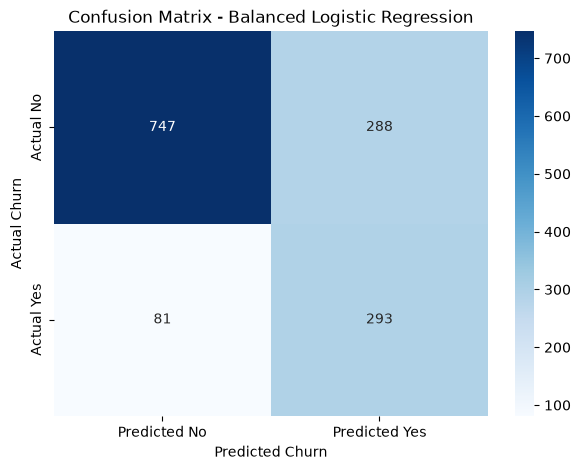

In [97]:
cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=["No", "Yes"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title("Confusion Matrix - Balanced Logistic Regression")
plt.xlabel("Predicted Churn")
plt.ylabel("Actual Churn")
plt.show()

## 20.Calculate precision, recall and F1-score
Calculate these metrics to quantify the improvement.

In [98]:
precision_balanced = precision_score(
    y_test, y_pred_balanced, pos_label="Yes"
)

recall_balanced = recall_score(
    y_test, y_pred_balanced, pos_label="Yes"
)

f1_balanced = f1_score(
    y_test, y_pred_balanced, pos_label="Yes"
)

print(f"Balanced Precision: {precision_balanced:.4f}")
print(f"Balanced Recall: {recall_balanced:.4f}")
print(f"Balanced F1-score: {f1_balanced:.4f}")

Balanced Precision: 0.5043
Balanced Recall: 0.7834
Balanced F1-score: 0.6136


## 21.### Interpretation: Balanced Logistic Regression Model

The balanced Logistic Regression model was introduced to address the class imbalance in the dataset by assigning higher weights to the minority class (customers who churned).

The model achieved an accuracy of 73.81%, which is lower than the original Logistic Regression model's accuracy of 80.55%.

However, the balanced model demonstrated a significant improvement in identifying customers who churned.

- **Precision (50.43%):** Of all customers predicted to churn, approximately 50% actually churned.
- **Recall (78.34%):** The model correctly identified approximately 78% of all actual churners.
- **F1-score (61.36%):** Indicates a slightly improved balance between precision and recall compared with the original model.

The confusion matrix also showed that the number of false negatives decreased from 165 to 81, meaning that the balanced model missed fewer actual churners.

However, false positives increased from 109 to 288, indicating that more customers who would have stayed were incorrectly classified as potential churners.

Overall, class weighting improved the model's ability to identify potential churners, although this came at the expense of precision and overall accuracy.

This demonstrates the trade-off between precision and recall when addressing class imbalance.

# Part I : Model Optimisation and Improvement

## This section focuses on improving the baseline Logistic Regression model through different optimisation techniques.

The following approaches will be explored:

- **Decision Threshold Tuning:** Experimenting with different classification thresholds to find a better balance between precision and recall.
- **Alternative Classification Algorithms:** Exploring models such as Random Forest and Gradient Boosting to determine whether they offer better predictive performance.

The objective is to improve the model's ability to identify customers who are likely to churn while maintaining a reasonable balance between false positives and false negatives.

## 1.Retrieve churn probabilities
Logistic Regression produces probabilities before assigning a final class (Yes or No).

We previously used predict_proba() to obtain these probabilities for ROC-AUC.

Let's retrieve them again from our original, unbalanced Logistic Regression model.

In [99]:
yes_index = list(logistic_model.classes_).index("Yes")

y_prob = logistic_model.predict_proba(X_test_processed)[:, yes_index]

print(y_prob[:10])

[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


## 2.Experiment with a new threshold
Use a threshold of 0.4.

In [100]:
threshold = 0.4

y_pred_threshold = np.where(y_prob >= threshold, "Yes", "No")

print(y_pred_threshold[:10])

['No' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'No' 'No' 'No']


## 3.Evaluate the new threshold
Calculate the precision, recall, F1-score and accuracy using the new predictions.

In [101]:
accuracy_threshold = accuracy_score(y_test, y_pred_threshold)
precision_threshold = precision_score(y_test, y_pred_threshold, pos_label="Yes")
recall_threshold = recall_score(y_test, y_pred_threshold, pos_label="Yes")
f1_threshold = f1_score(y_test, y_pred_threshold, pos_label="Yes")

print(f"Accuracy:  {accuracy_threshold:.4f}")
print(f"Precision: {precision_threshold:.4f}")
print(f"Recall:    {recall_threshold:.4f}")
print(f"F1-score:  {f1_threshold:.4f}")

Accuracy:  0.7771
Precision: 0.5682
Recall:    0.6684
F1-score:  0.6143


## 4.Comparison of Logistic Regression Models

The following table compares the performance of the original Logistic Regression model, the model using a reduced classification threshold of 0.4, and the balanced Logistic Regression model.

| Metric | Original (0.5) | Threshold (0.4) | Balanced (0.5) |
|---|---:|---:|---:|
| Accuracy | 80.55% | 77.71% | 73.81% |
| Precision | 65.72% | 56.82% | 50.43% |
| Recall | 55.88% | 66.84% | 78.34% |
| F1-score | 60.40% | **61.43%** | 61.36% |

### Interpretation

- **Accuracy:** The original model achieved the highest accuracy of 80.55%.
- **Precision:** The original model achieved the highest precision of 65.72%.
- **Recall:** The balanced model achieved the highest recall of 78.34%, identifying the greatest proportion of actual churners.
- **F1-score:** The model using a threshold of 0.4 achieved the highest F1-score of 61.43%, indicating the best balance between precision and recall among the three approaches.

Overall, lowering the classification threshold from 0.5 to 0.4 improved recall and F1-score compared with the original model. The balanced model achieved higher recall but at the expense of precision and accuracy.

These results demonstrate the trade-off between precision and recall when adjusting classification thresholds and applying class weighting.

## 5.Experiment with a threshold of 0.3

In [102]:
threshold = 0.3

y_pred_threshold_03 = np.where(y_prob >= threshold, "Yes", "No")

accuracy_03 = accuracy_score(y_test, y_pred_threshold_03)
precision_03 = precision_score(y_test, y_pred_threshold_03, pos_label="Yes")
recall_03 = recall_score(y_test, y_pred_threshold_03, pos_label="Yes")
f1_03 = f1_score(y_test, y_pred_threshold_03, pos_label="Yes")

print(f"Accuracy:  {accuracy_03:.4f}")
print(f"Precision: {precision_03:.4f}")
print(f"Recall:    {recall_03:.4f}")
print(f"F1-score:  {f1_03:.4f}")

Accuracy:  0.7495
Precision: 0.5193
Recall:    0.7540
F1-score:  0.6150


1. Accuracy (74.95%): Lower than the original model's accuracy of 80.55%.
2. Precision (51.93%): Approximately 52% of customers predicted to churn actually churned.
3. Recall (75.40%): The model correctly identifies approximately 75% of actual churners.
4. F1-score (61.50%): Currently the highest F1-score among the approaches tested.
Important observation
As we lower the classification threshold:
- Recall increases because more customers are classified as potential churners.
- Precision decreases because more customers who would actually stay are incorrectly flagged.
- F1-score does not necessarily increase indefinitely.
The difference between the F1-scores at 0.3 and 0.4 is very small (0.07 percentage points).

## 6.Experiment with threshold 0.35

In [103]:
threshold = 0.35

y_pred_threshold_035 = np.where(y_prob >= threshold, "Yes", "No")

accuracy_035 = accuracy_score(y_test, y_pred_threshold_035)
precision_035 = precision_score(y_test, y_pred_threshold_035, pos_label="Yes")
recall_035 = recall_score(y_test, y_pred_threshold_035, pos_label="Yes")
f1_035 = f1_score(y_test, y_pred_threshold_035, pos_label="Yes")

print(f"Accuracy:  {accuracy_035:.4f}")
print(f"Precision: {precision_035:.4f}")
print(f"Recall:    {recall_035:.4f}")
print(f"F1-score:  {f1_035:.4f}")

Accuracy:  0.7644
Precision: 0.5432
Recall:    0.7059
F1-score:  0.6140


## 7.Visualising threshold performance
We have tested four classification thresholds: 0.50, 0.40, 0.35 and 0.30.

Let's visualise how precision, recall and F1-score change as the threshold decreases.

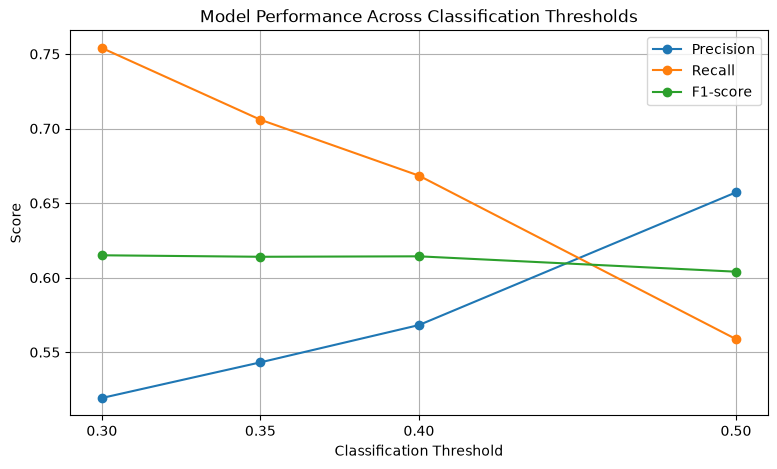

In [104]:
thresholds = [0.30, 0.35, 0.40, 0.50]

precision_values = [0.5193, 0.5432, 0.5682, 0.6572]
recall_values = [0.7540, 0.7059, 0.6684, 0.5588]
f1_values = [0.6150, 0.6140, 0.6143, 0.6040]

plt.figure(figsize=(9, 5))

plt.plot(thresholds, precision_values, marker="o", label="Precision")
plt.plot(thresholds, recall_values, marker="o", label="Recall")
plt.plot(thresholds, f1_values, marker="o", label="F1-score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Model Performance Across Classification Thresholds")
plt.xticks(thresholds)
plt.legend()
plt.grid(True)
plt.show()

### Interpretation: Decision Threshold Tuning

Decision threshold tuning was performed to investigate how changing the classification threshold affects the Logistic Regression model's predictive performance.

The original Logistic Regression model uses a default threshold of 0.5. Lower thresholds were tested to investigate whether the model could identify a greater proportion of customers who are likely to churn.

The results demonstrate the following:

- **Precision:** Generally increases as the classification threshold increases because fewer customers are classified as potential churners.
- **Recall:** Generally decreases as the classification threshold increases because fewer actual churners are identified.
- **F1-score:** Provides a balance between precision and recall and helps assess the overall performance of the model.

Among the thresholds tested, 0.3 achieved the highest F1-score of 61.50%, compared with 60.40% at the original threshold of 0.5.

The threshold of 0.3 also achieved a recall of 75.40%, indicating that the model identified a greater proportion of actual churners. However, this improvement came at the expense of precision, which decreased to 51.93%.

Overall, reducing the classification threshold improved the model's ability to identify potential churners, although it also increased the number of false positive predictions.

The threshold of 0.3 currently provides the highest F1-score among the tested thresholds. However, further evaluation using validation data is required before selecting a final classification threshold.

## 8.Conclusion: Model Optimisation

The Logistic Regression model was optimised using class weighting and decision threshold tuning to investigate ways of improving its ability to identify customers who are likely to churn.

The results demonstrated a trade-off between precision and recall.

The original Logistic Regression model achieved the highest accuracy (80.55%) and precision (65.72%), but had a relatively low recall of 55.88%.

Applying class weighting improved recall to 78.34%, but reduced precision to 50.43%.

Decision threshold tuning also improved the model's ability to identify potential churners. Among the thresholds tested, a threshold of 0.3 achieved the highest F1-score of 61.50%, with a recall of 75.40%.

Overall, threshold tuning at 0.3 provided the best balance between precision and recall among the approaches evaluated, although the improvement in F1-score was relatively small.

The original Logistic Regression model will be retained as the baseline, while the 0.3 threshold will be considered a candidate for further evaluation.

Further improvements will be explored through feature selection and alternative classification algorithms.

# Part J : Feature Selection Using AIC

In [106]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

print("Statsmodels version:", sm.__version__)

Statsmodels version: 0.15.0


## 1.Prepare the training data
### Preparing Data for Feature Selection

Feature selection will be performed using the training dataset only to prevent information from the test dataset influencing the selection process.

The target variable, `Churn`, will be converted into binary numerical values:
- No = 0
- Yes = 1

In [115]:
# Create a copy of the training predictors
train_data = X_train.copy()

# Add the target variable as a binary numerical column
train_data["Churn"] = (y_train == "Yes").astype(int)

# Inspect the prepared dataset
print("Training data shape:", train_data.shape)
print(train_data["Churn"].value_counts())

Training data shape: (5634, 20)
Churn
0    4139
1    1495
Name: count, dtype: int64


## 2.Identifying Predictor Types

The predictors will be separated into numerical and categorical variables.

This distinction is important because numerical variables are included directly in the logistic regression formula, while categorical variables must be encoded as categorical terms using Statsmodels' `C()` notation.

In [116]:
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 3.Creating the Full Logistic Regression Formula

A logistic regression formula specifies the dependent variable and the independent variables included in the model.

Numerical predictors are included directly, while categorical predictors are wrapped in `C()` so that Statsmodels treats them as categorical variables.

In [117]:
# Start with numerical predictors
feature_terms = numerical_features.copy()

# Add categorical predictors using C()
feature_terms += [f"C({feature})" for feature in categorical_features]

# Construct the full model formula
full_formula = "Churn ~ " + " + ".join(feature_terms)

print(full_formula)

Churn ~ SeniorCitizen + tenure + MonthlyCharges + TotalCharges + C(gender) + C(Partner) + C(Dependents) + C(PhoneService) + C(MultipleLines) + C(InternetService) + C(OnlineSecurity) + C(OnlineBackup) + C(DeviceProtection) + C(TechSupport) + C(StreamingTV) + C(StreamingMovies) + C(Contract) + C(PaperlessBilling) + C(PaymentMethod)


## 4.Standardise the overlapping categorical categories
### Standardising Categorical Variables

Some categorical predictors contain overlapping categories that represent the absence of a service.

For example:
- `MultipleLines` contains the category "No phone service", which overlaps with `PhoneService = No`.
- Internet-dependent services contain the category "No internet service", which overlaps with `InternetService = No`.

These overlapping categories introduce perfect linear dependencies when categorical variables are encoded in the logistic regression model.

To address this issue, the overlapping categories are standardised to "No". This removes redundant category information while retaining all 19 original predictors.

This preparation allows the logistic regression model to estimate its parameters without the singular matrix issue encountered during the initial model fitting attempt.

In [119]:
# Standardise categories representing the absence of a service

train_data["MultipleLines"] = train_data["MultipleLines"].replace(
    "No phone service", "No"
)

internet_features = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

for feature in internet_features:
    train_data[feature] = train_data[feature].replace(
        "No internet service", "No"
    )

print("Categorical categories standardised.")

Categorical categories standardised.


## 5.Fit the full regression model

In [120]:
full_model = smf.logit(
    formula=full_formula,
    data=train_data
).fit()

print("Full Model AIC:", full_model.aic)

Optimization terminated successfully.
         Current function value: 0.412375
         Iterations 8
Full Model AIC: 4694.638558605035


## 6.Forward Selection

Forward selection is a feature selection technique that starts with an intercept-only model and progressively adds predictors.

At each iteration:
1. Each remaining predictor is added individually to the current model.
2. The AIC is calculated for every candidate model.
3. The predictor producing the lowest AIC is selected.
4. The process continues until no remaining predictor improves the AIC.

The objective is to identify a smaller subset of predictors that provides a good balance between model fit and complexity.

### 6.1: Fit the intercept-only model

In [121]:
# Fit an intercept-only logistic regression model
null_model = smf.logit(
    formula="Churn ~ 1",
    data=train_data
).fit()

print("Intercept-only model AIC:", null_model.aic)

Optimization terminated successfully.
         Current function value: 0.578582
         Iterations 5
Intercept-only model AIC: 6521.462703668312


### 6.2: Implement the Forward Selection algorithm

In [124]:
def forward_selection(data, numerical_features, categorical_features):

    selected_features = []
    remaining_features = numerical_features + categorical_features

    current_aic = smf.logit(
        formula="Churn ~ 1",
        data=data
    ).fit(disp=False).aic

    while remaining_features:

        candidate_aics = []

        for feature in remaining_features:

            term = (
                f"C({feature})"
                if feature in categorical_features
                else feature
            )

            selected_terms = [
                f"C({selected})"
                if selected in categorical_features
                else selected
                for selected in selected_features
            ]

            formula = "Churn ~ " + " + ".join(
                selected_terms + [term]
            )

            model = smf.logit(
                formula=formula,
                data=data
            ).fit(disp=False)

            candidate_aics.append((feature, model.aic))

        best_feature, best_aic = min(
            candidate_aics,
            key=lambda item: item[1]
        )

        if best_aic < current_aic:

            selected_features.append(best_feature)
            remaining_features.remove(best_feature)
            current_aic = best_aic

            print(f"Added: {best_feature} | AIC: {best_aic:.2f}")

        else:
            break

    return selected_features, current_aic

### 6.3: Run Forward Selection

In [125]:
selected_forward, forward_aic = forward_selection(
    train_data,
    numerical_features,
    categorical_features
)

print("\nSelected predictors:", selected_forward)
print("Final Forward Selection AIC:", forward_aic)
print("Number of selected predictors:", len(selected_forward))

Added: Contract | AIC: 5411.59
Added: InternetService | AIC: 5070.27
Added: tenure | AIC: 4861.10
Added: PaymentMethod | AIC: 4819.16
Added: PaperlessBilling | AIC: 4787.93
Added: OnlineSecurity | AIC: 4765.87
Added: StreamingMovies | AIC: 4746.09
Added: TechSupport | AIC: 4734.07
Added: TotalCharges | AIC: 4724.27
Added: PhoneService | AIC: 4713.10
Added: MultipleLines | AIC: 4704.25
Added: Dependents | AIC: 4699.42
Added: StreamingTV | AIC: 4695.36
Added: MonthlyCharges | AIC: 4691.20
Added: SeniorCitizen | AIC: 4690.71
Added: DeviceProtection | AIC: 4690.27

Selected predictors: ['Contract', 'InternetService', 'tenure', 'PaymentMethod', 'PaperlessBilling', 'OnlineSecurity', 'StreamingMovies', 'TechSupport', 'TotalCharges', 'PhoneService', 'MultipleLines', 'Dependents', 'StreamingTV', 'MonthlyCharges', 'SeniorCitizen', 'DeviceProtection']
Final Forward Selection AIC: 4690.266690605042
Number of selected predictors: 16


### Forward Selection Results

Forward selection identified 16 predictors from the original 19 predictors.

The selected predictors were:

- Contract
- InternetService
- tenure
- PaymentMethod
- PaperlessBilling
- OnlineSecurity
- StreamingMovies
- TechSupport
- TotalCharges
- PhoneService
- MultipleLines
- Dependents
- StreamingTV
- MonthlyCharges
- SeniorCitizen
- DeviceProtection

The following predictors were excluded:

- gender
- Partner
- OnlineBackup

The final forward-selected model achieved an AIC of 4690.27, compared with an AIC of 4694.64 for the full model.

This suggests that removing the three excluded predictors slightly improved the balance between model fit and complexity.

## 7.Backward Elimination

Backward elimination is a feature selection technique that starts with a full model containing all available predictors and progressively removes predictors.

At each iteration:

1. Each remaining predictor is removed individually from the current model.
2. The AIC is calculated for every candidate model.
3. The predictor whose removal produces the lowest AIC is eliminated.
4. The process continues until removing any remaining predictor no longer improves the AIC.

The objective is to identify a smaller subset of predictors that provides a good balance between model fit and complexity.

### 7.1: Implement the Backward Elimination Algorithm

In [126]:
def backward_elimination(data, numerical_features, categorical_features):

    selected_features = numerical_features + categorical_features

    current_aic = smf.logit(
        formula=full_formula,
        data=data
    ).fit(disp=False).aic

    while selected_features:

        candidate_aics = []

        for feature in selected_features:

            remaining = [
                selected for selected in selected_features
                if selected != feature
            ]

            terms = [
                f"C({selected})"
                if selected in categorical_features
                else selected
                for selected in remaining
            ]

            formula = (
                "Churn ~ " + " + ".join(terms)
                if terms else "Churn ~ 1"
            )

            model = smf.logit(
                formula=formula,
                data=data
            ).fit(disp=False)

            candidate_aics.append((feature, model.aic))

        removed_feature, best_aic = min(
            candidate_aics,
            key=lambda item: item[1]
        )

        if best_aic < current_aic:

            selected_features.remove(removed_feature)
            current_aic = best_aic

            print(
                f"Removed: {removed_feature} | AIC: {best_aic:.2f}"
            )

        else:
            break

    return selected_features, current_aic

### 7.2: Run Backward Elimination

In [127]:
selected_backward, backward_aic = backward_elimination(
    train_data,
    numerical_features,
    categorical_features
)

print("\nSelected predictors:", selected_backward)
print("Final Backward Elimination AIC:", backward_aic)
print("Number of selected predictors:", len(selected_backward))

Removed: OnlineSecurity | AIC: 4692.64
Removed: Partner | AIC: 4690.70
Removed: gender | AIC: 4688.81
Removed: TechSupport | AIC: 4686.97

Selected predictors: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineBackup', 'DeviceProtection', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Final Backward Elimination AIC: 4686.969897306863
Number of selected predictors: 15


### Backward Elimination Results

Backward elimination started with all 19 predictors and removed four predictors:

- OnlineSecurity
- Partner
- gender
- TechSupport

The final model retained 15 predictors.

The backward elimination model achieved an AIC of 4686.97, compared with:

- Full model: 4694.64
- Forward selection: 4690.27

Backward elimination achieved the lowest AIC among the three models evaluated so far.

This suggests that removing the four excluded predictors improved the balance between model fit and complexity.

The results also demonstrate that forward selection and backward elimination can identify different predictor subsets because they follow different selection paths.

## 8.Stepwise Selection

Stepwise selection combines forward selection and backward elimination.

It begins with an intercept-only model and progressively adds predictors that improve the AIC. After each addition, it checks whether removing any previously selected predictor would further reduce the AIC.

At each iteration:

1. Identify the predictor whose addition produces the lowest AIC.
2. Add that predictor if it improves the current model.
3. Check whether removing any selected predictor improves the AIC.
4. Repeat until no further addition or removal improves the AIC.

The objective is to identify a predictor subset that provides a good balance between model fit and complexity.

### 8.1: Implement Stepwise selection

In [128]:
def stepwise_selection(data, numerical_features, categorical_features):

    selected_features = []
    remaining_features = numerical_features + categorical_features

    current_aic = smf.logit(
        formula="Churn ~ 1",
        data=data
    ).fit(disp=False).aic

    changed = True

    while changed:

        changed = False

        # Forward step: find the best predictor to add
        candidate_aics = []

        for feature in remaining_features:

            term = (
                f"C({feature})"
                if feature in categorical_features
                else feature
            )

            selected_terms = [
                f"C({selected})"
                if selected in categorical_features
                else selected
                for selected in selected_features
            ]

            formula = "Churn ~ " + " + ".join(
                selected_terms + [term]
            )

            model = smf.logit(
                formula=formula,
                data=data
            ).fit(disp=False)

            candidate_aics.append((feature, model.aic))

        if candidate_aics:

            best_feature, best_aic = min(
                candidate_aics,
                key=lambda item: item[1]
            )

            if best_aic < current_aic:

                selected_features.append(best_feature)
                remaining_features.remove(best_feature)
                current_aic = best_aic
                changed = True

                print(
                    f"Added: {best_feature} | AIC: {best_aic:.2f}"
                )

        # Backward step: check whether a selected predictor can be removed
        while selected_features:

            candidate_aics = []

            for feature in selected_features:

                remaining = [
                    selected for selected in selected_features
                    if selected != feature
                ]

                terms = [
                    f"C({selected})"
                    if selected in categorical_features
                    else selected
                    for selected in remaining
                ]

                formula = (
                    "Churn ~ " + " + ".join(terms)
                    if terms else "Churn ~ 1"
                )

                model = smf.logit(
                    formula=formula,
                    data=data
                ).fit(disp=False)

                candidate_aics.append((feature, model.aic))

            removed_feature, best_aic = min(
                candidate_aics,
                key=lambda item: item[1]
            )

            if best_aic < current_aic:

                selected_features.remove(removed_feature)
                remaining_features.append(removed_feature)
                current_aic = best_aic

                changed = True

                print(
                    f"Removed: {removed_feature} | AIC: {best_aic:.2f}"
                )

            else:
                break

    return selected_features, current_aic

### 8.2: Run Stepwise Selection

In [129]:
selected_stepwise, stepwise_aic = stepwise_selection(
    train_data,
    numerical_features,
    categorical_features
)

print("\nSelected predictors:", selected_stepwise)
print("Final Stepwise Selection AIC:", stepwise_aic)
print("Number of selected predictors:", len(selected_stepwise))

Added: Contract | AIC: 5411.59
Added: InternetService | AIC: 5070.27
Added: tenure | AIC: 4861.10
Added: PaymentMethod | AIC: 4819.16
Added: PaperlessBilling | AIC: 4787.93
Added: OnlineSecurity | AIC: 4765.87
Added: StreamingMovies | AIC: 4746.09
Added: TechSupport | AIC: 4734.07
Added: TotalCharges | AIC: 4724.27
Added: PhoneService | AIC: 4713.10
Added: MultipleLines | AIC: 4704.25
Added: Dependents | AIC: 4699.42
Added: StreamingTV | AIC: 4695.36
Added: MonthlyCharges | AIC: 4691.20
Removed: PhoneService | AIC: 4689.20
Added: SeniorCitizen | AIC: 4688.71

Selected predictors: ['Contract', 'InternetService', 'tenure', 'PaymentMethod', 'PaperlessBilling', 'OnlineSecurity', 'StreamingMovies', 'TechSupport', 'TotalCharges', 'MultipleLines', 'Dependents', 'StreamingTV', 'MonthlyCharges', 'SeniorCitizen']
Final Stepwise Selection AIC: 4688.714134810427
Number of selected predictors: 14


### Stepwise Selection Results

Stepwise selection identified 14 predictors from the original 19 predictors.

The final model excluded:

- gender
- Partner
- OnlineBackup
- DeviceProtection
- PhoneService

The final stepwise model achieved an AIC of 4688.71.

During the selection process, PhoneService was initially added but subsequently removed because its removal improved the AIC.

Comparing the three feature selection methods:

- Forward selection: AIC of 4690.27 (16 predictors).
- Backward elimination: AIC of 4686.97 (15 predictors).
- Stepwise selection: AIC of 4688.71 (14 predictors).

Backward elimination achieved the lowest AIC, while stepwise selection produced the smallest predictor subset.

These results demonstrate that different feature selection strategies can identify different predictor subsets depending on their selection procedures.

## 9.Interaction Effects

Interaction effects occur when the relationship between one predictor and the target variable depends on the value of another predictor.

In logistic regression, interaction terms allow the model to capture relationships that cannot necessarily be explained by considering each predictor independently.

For example:

- Contract × InternetService: The relationship between contract type and customer churn may differ depending on the internet service used.
- Contract × PaymentMethod: The relationship between contract type and churn may differ depending on the payment method.
- tenure × MonthlyCharges: The relationship between monthly charges and churn may depend on how long a customer has been with the company.

Interaction effects can improve model fit by capturing more complex relationships between predictors.

In this section, selected interaction terms will be evaluated using AIC to determine whether they improve the model.

### 9.1: Select Candidate Interactions

In [130]:
candidate_interactions = [
    "C(Contract):C(InternetService)",
    "C(Contract):C(PaymentMethod)",
    "tenure:MonthlyCharges",
    "C(InternetService):C(OnlineSecurity)"
]

print("Candidate interaction terms:")

for interaction in candidate_interactions:
    print(interaction)

Candidate interaction terms:
C(Contract):C(InternetService)
C(Contract):C(PaymentMethod)
tenure:MonthlyCharges
C(InternetService):C(OnlineSecurity)


Why these four?
- Contract and InternetService may capture differences in churn across service and contract combinations.
- Contract and PaymentMethod may capture differences in customer commitment and payment behaviour.
- tenure and MonthlyCharges may capture how the relationship between charges and churn changes over time.
- InternetService and OnlineSecurity may capture differences in security-service availability and usage.
We'll evaluate these interactions against our best main-effects model from backward elimination (AIC = 4686.97).

### 9.2: Fit the Main-Effects Model
Before testing interactions, we'll use the backward elimination model as our reference model.

In [133]:
backward_terms = [
    f"C({feature})"
    if feature in categorical_features
    else feature
    for feature in selected_backward
]

backward_formula = "Churn ~ " + " + ".join(backward_terms)

backward_model = smf.logit(
    formula=backward_formula,
    data=train_data
).fit(disp=False)

print(f"Main-effects model AIC: {backward_model.aic:.4f}")

Main-effects model AIC: 4686.9699


### 9.3: Evaluate Interactions Individually
Fit a separate model for each interaction, keeping all 15 predictors from backward elimination.

In [135]:
interaction_results = []

for interaction in candidate_interactions:

    formula = backward_formula + " + " + interaction

    try:
        model = smf.logit(
            formula=formula,
            data=train_data
        ).fit(disp=False)

        interaction_results.append({
            "Interaction": interaction,
            "AIC": model.aic,
            "AIC Improvement": backward_model.aic - model.aic
        })

    except (np.linalg.LinAlgError, Exception) as error:
        print(f"Could not fit {interaction}: {error}")

interaction_results_df = pd.DataFrame(interaction_results)

interaction_results_df

Could not fit C(InternetService):C(OnlineSecurity): Singular matrix


,Interaction,AIC,AIC Improvement
0,C(Contract):C(InternetService),4688.084446,-1.114549
1,C(Contract):C(PaymentMethod),4691.450198,-4.480301
2,tenure:MonthlyCharges,4688.693001,-1.723104


### Interaction Effects Results

Four candidate interaction terms were evaluated against the backward elimination model.

Three interaction models were successfully fitted:

- Contract × InternetService: AIC of 4688.08.
- Contract × PaymentMethod: AIC of 4691.45.
- tenure × MonthlyCharges: AIC of 4688.69.

The InternetService × OnlineSecurity interaction could not be fitted because of a singular matrix.

The main-effects model achieved an AIC of 4686.9699, which was lower than the AIC of all three successfully fitted interaction models.

This indicates that the evaluated interactions did not improve the balance between model fit and complexity.

Consequently, the main-effects model was retained without the tested interaction terms.

## 10.Feature Selection Summary

Three AIC-based feature selection techniques were evaluated:

| Method | Predictors Retained | AIC |
|---|---:|---:|
| Full model | 19 | 4694.64 |
| Forward selection | 16 | 4690.27 |
| Backward elimination | 15 | 4686.97 |
| Stepwise selection | 14 | 4688.71 |

Backward elimination achieved the lowest AIC of 4686.97, retaining 15 predictors.

Interaction effects were also investigated. None of the successfully fitted interaction models achieved a lower AIC than the main-effects model.

Therefore, the backward elimination model was selected as the preferred model based on AIC.

The selected predictors will be considered in subsequent modelling and evaluation.

# Part K : Alternative Predictive Models

In this section, alternative machine learning algorithms will be developed to predict customer churn.

The models selected are:

- Random Forest Classifier
- Gradient Boosting Classifier

These algorithms use ensemble learning techniques to combine multiple decision trees and capture potentially complex relationships between customer attributes and churn.

Their predictive performance will be compared with the Logistic Regression models developed in Part H.

The same training and testing datasets will be used to ensure a consistent comparison.

## 1.Import the Algorithms

In [136]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

## 2.Build the Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions.

Each tree is trained using a random sample of the training data and a random subset of features.

For classification, the individual trees vote on the predicted class, and the majority vote determines the final prediction.

Random Forest can capture non-linear relationships and interactions between predictors, making it useful for identifying complex customer churn patterns.

### 2.1: Initialise and Train the Model

In [137]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

random_forest_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

### 2.2: Generate Random Forest Predictions

In [138]:
y_pred_rf = random_forest_model.predict(X_test_processed)

y_prob_rf = random_forest_model.predict_proba(X_test_processed)[:, 1]

### 2.3: Evaluate the Random Forest Model
We'll calculate the same classification metrics used for Logistic Regression so that our comparison is consistent.

In [140]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label="Yes")
rf_recall = recall_score(y_test, y_pred_rf, pos_label="Yes")
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="Yes")
rf_roc_auc = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_prob_rf
)

print(f"Accuracy:  {rf_accuracy * 100:.2f}%")
print(f"Precision: {rf_precision * 100:.2f}%")
print(f"Recall:    {rf_recall * 100:.2f}%")
print(f"F1-score:  {rf_f1 * 100:.2f}%")
print(f"ROC-AUC:   {rf_roc_auc * 100:.2f}%")

Accuracy:  77.00%
Precision: 55.92%
Recall:    63.10%
F1-score:  59.30%
ROC-AUC:   82.13%


### Random Forest Model Evaluation

The Random Forest classifier achieved an accuracy of 77.00%, precision of 55.92%, recall of 63.10%, F1-score of 59.30%, and ROC-AUC of 82.13%.

The model correctly classified 77% of customers in the test dataset and identified approximately 63% of actual churners.

Compared with the baseline Logistic Regression model, Random Forest achieved higher recall but lower accuracy, precision, F1-score, and ROC-AUC.

This suggests that Random Forest identifies more customers who are likely to churn, although it also produces more false positive predictions.

The results demonstrate the trade-off between identifying churners and avoiding incorrect churn predictions.

## 3.Build the Gradient Boosting Classifier

Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially.

Unlike Random Forest, where trees are built independently, Gradient Boosting trains each new tree to correct errors made by the previous trees.

The predictions from the individual trees are combined to produce the final prediction.

This approach allows the model to capture complex, non-linear relationships between customer attributes and churn.

### 3.1: Initialise and Train the Model

In [141]:
gradient_boosting_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gradient_boosting_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

### 3.2: Generate Predictions

In [142]:
y_pred_gb = gradient_boosting_model.predict(X_test_processed)

y_prob_gb = gradient_boosting_model.predict_proba(X_test_processed)[:, 1]

### 3.3: Evaluate Model Performance

In [143]:
gb_accuracy = accuracy_score(y_test, y_pred_gb)
gb_precision = precision_score(y_test, y_pred_gb, pos_label="Yes")
gb_recall = recall_score(y_test, y_pred_gb, pos_label="Yes")
gb_f1 = f1_score(y_test, y_pred_gb, pos_label="Yes")

gb_roc_auc = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_prob_gb
)

print(f"Accuracy:  {gb_accuracy * 100:.2f}%")
print(f"Precision: {gb_precision * 100:.2f}%")
print(f"Recall:    {gb_recall * 100:.2f}%")
print(f"F1-score:  {gb_f1 * 100:.2f}%")
print(f"ROC-AUC:   {gb_roc_auc * 100:.2f}%")

Accuracy:  80.27%
Precision: 66.55%
Recall:    51.60%
F1-score:  58.13%
ROC-AUC:   84.34%


### Gradient Boosting Model Evaluation

The Gradient Boosting classifier achieved an accuracy of 80.27%, precision of 66.55%, recall of 51.60%, F1-score of 58.13%, and ROC-AUC of 84.34%.

The model correctly classified approximately 80% of customers and demonstrated good ability to distinguish between customers who churn and those who stay.

Compared with the baseline Logistic Regression model, Gradient Boosting achieved slightly higher precision and ROC-AUC, but lower accuracy, recall, and F1-score.

Although Gradient Boosting performed well in distinguishing between churners and non-churners, its relatively low recall indicates that it missed a considerable proportion of actual churners.

# Part L : Final Model Comparison.

### In this section, the predictive performance of the developed machine learning models will be compared to identify the most suitable model for customer churn prediction.

The models being evaluated include:

- Baseline Logistic Regression
- Balanced Logistic Regression
- Threshold-adjusted Logistic Regression (0.4, 0.35 and 0.3)
- Random Forest Classifier
- Gradient Boosting Classifier

The models will be compared using accuracy, precision, recall, F1-score and ROC-AUC.

Since identifying customers who are likely to churn is an important objective, particular attention will be given to recall and F1-score, while also considering the trade-off between identifying churners and generating false positive predictions

## 1.Create the Model Comparison DataFrame

In [148]:
y_prob_balanced = balanced_logistic_model.predict_proba(
    X_test_processed
)[:, list(balanced_logistic_model.classes_).index("Yes")]

balanced_roc_auc = roc_auc_score(
    (y_test == "Yes").astype(int),
    y_prob_balanced
)

print(f"Balanced Logistic Regression ROC-AUC: {balanced_roc_auc * 100:.2f}%")

Balanced Logistic Regression ROC-AUC: 84.16%


In [149]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Balanced Logistic Regression",
        "Logistic Regression (Threshold 0.4)",
        "Logistic Regression (Threshold 0.35)",
        "Logistic Regression (Threshold 0.3)",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        0.8055, 0.7381, 0.7771, 0.7644, 0.7495,
        rf_accuracy, gb_accuracy
    ],
    "Precision": [
        0.6572, 0.5043, 0.5682, 0.5432, 0.5193,
        rf_precision, gb_precision
    ],
    "Recall": [
        0.5588, 0.7834, 0.6684, 0.7059, 0.7540,
        rf_recall, gb_recall
    ],
    "F1-score": [
        0.6040, 0.6136, 0.6143, 0.6140, 0.6150,
        rf_f1, gb_f1
    ],
    "ROC-AUC": [
        0.8421, balanced_roc_auc, 0.8421, 0.8421, 0.8421,
        rf_roc_auc, gb_roc_auc
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8421
1,Balanced Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8416
2,Logistic Regression (Threshold 0.4),0.7771,0.5682,0.6684,0.6143,0.8421
3,Logistic Regression (Threshold 0.35),0.7644,0.5432,0.7059,0.6140,0.8421
4,Logistic Regression (Threshold 0.3),0.7495,0.5193,0.7540,0.6150,0.8421
5,Random Forest,0.7700,0.5592,0.6310,0.5930,0.8213
6,Gradient Boosting,0.8027,0.6655,0.5160,0.5813,0.8434


### Interpretation of Model Comparison

The comparison shows that no single model performs best across all evaluation metrics.

The baseline Logistic Regression model achieved the highest accuracy of 80.55%, while Gradient Boosting achieved the highest precision of 66.55% and ROC-AUC of 84.34%.

Balanced Logistic Regression achieved the highest recall of 78.34%, indicating that it identifies a larger proportion of actual churners.

Logistic Regression with a classification threshold of 0.3 achieved the highest F1-score of 61.50%, demonstrating the best balance between precision and recall among the evaluated configurations.

Overall, the results highlight the importance of selecting a model based on the business objective rather than relying on accuracy alone. Since identifying customers at risk of churn is a key objective, recall and F1-score are particularly important evaluation metrics.

# Part M : Final Evaluation and Project Conclusions

### 1.Final Model Selection

Based on the evaluation results, Balanced Logistic Regression is selected as the preferred model when the primary objective is identifying customers who are likely to churn.

It achieved the highest recall of 78.34%, identifying a larger proportion of actual churners than the other evaluated models.

However, this improvement in recall comes at the cost of precision, which decreased to 50.43%. This means that the model generates more false positive predictions.

For a telecommunications company, this trade-off may be acceptable because identifying customers at risk of leaving creates opportunities for targeted retention strategies.

Therefore, Balanced Logistic Regression is selected as the preferred model for churn identification, although the final choice should also consider the cost of false positive predictions and the resources available for customer retention campaigns.

### 2.Overall Project Conclusion

This project analysed customer churn in a telecommunications company using data analysis, statistical hypothesis testing, feature engineering and machine learning techniques.

The exploratory data analysis identified several patterns associated with customer churn. Customers with shorter tenure, higher monthly charges and month-to-month contracts demonstrated higher churn rates.

Statistical analysis further established significant associations between customer churn and several customer attributes, including contract type, internet service, payment method and additional services.

Multiple predictive models were developed and evaluated. Although Logistic Regression, Random Forest and Gradient Boosting demonstrated reasonable predictive performance, Balanced Logistic Regression achieved the highest recall of 78.34%.

The findings demonstrate how data science and machine learning can support customer retention by identifying customers who are more likely to leave.

Ultimately, the project highlights the importance of combining exploratory analysis, statistical methods and predictive modelling to extract meaningful insights and support data-driven business decisions.

### 3.Project Limitations

Despite the insights obtained from the analysis, several limitations should be considered:

1. **Class imbalance:** The dataset contains more customers who stayed than customers who churned. Although class weighting was used to address this imbalance, it may still affect model performance.

3. **Model performance:** Although Balanced Logistic Regression achieved the highest recall, its precision was relatively low. This means that some customers identified as potential churners may not actually leave.

4. **Dataset limitations:** The analysis is based on the available customer dataset. Additional information, such as customer satisfaction, complaints and competitor activity, could provide further insights into the factors influencing churn.

5. **Association versus causation:** The statistical relationships identified in the analysis do not establish that the observed customer attributes directly cause churn.